# Проект: Исследование стартапов

<a id='beginning'></a>

## Оглавление

1. [Введение](#intro)
2. [Описание данных](#description)
3. [Знакомство с данными: загрузка и предобработка](#data_pre)
4. [Инжиниринг признаков](#data_engeneer)
5. [Работа с выбросами и анализ данных](#data_analys)
6. [Анализ динамики](#dynamic_analysis)
7. [Итоговый вывод и рекомендации](#conclusion)

<a id='intro'></a>

## Введение

### Описание исследования

Финансовая компания, специализирующаяся на венчурных инвестициях, планирует изучить особенности финансирования стартапов и оценить перспективы возврата вложенного капитала. Исследование исторических данных позволит проанализировать сведения о компаниях, объёмы привлечённых ими инвестиций и показатели возврата средств.

В работе будут использованы два датасета: первый содержит информацию о компаниях и состоянии их финансирования, второй — данные об объёмах возврата средств в разрезе лет и типов финансирования.

### Цель исследования

Подготовить данные к анализу, изучить динамику и структуру финансирования стартапов и сформулировать выводы, которые помогут оценить инвестиционные стратегии.

### Задачи проекта

В рамках проекта предстоит:

- провести предобработку данных: удалить дубликаты и пропуски, проверить корректность числовых и временных значений;
- выделить группы компаний по срокам финансирования и сравнить их по количеству и объёму инвестиций;
- классифицировать сегменты рынка на массовые, средние и нишевые и учесть это в дальнейшем анализе;
- определить типичные и аномальные значения объёмов финансирования, исключить выбросы и ограничить период исследования;
- сравнить популярность и объёмы разных типов финансирования;
- проанализировать динамику рынка и объёмов инвестиций по годам, а также изменения в массовых сегментах рынка;
- рассчитать доходность возврата средств для разных типов финансирования и оценить её устойчивость;
- подвести итоговые выводы и дать рекомендации, куда и каким образом было бы целесообразно инвестировать, если бы на дворе был 2015 год.

<a id='description'></a>

## Описание данных

В проекте используются два датасета о венчурном финансировании стартапов.

### 1. Данные о компаниях и состоянии финансирования

**Файл:** `ds_investments.csv`

Датасет содержит информацию о компаниях и состоянии их финансирования:

- `name` — название компании;
- `homepage_url` — ссылка на сайт компании;
- `category_list` — категории, в которых работает компания. Указывается через `|`;
- `market` — основной рынок или отрасль компании;
- `funding_total_usd` — общий объём привлечённых инвестиций в долларах США;
- `status` — текущий статус компании, например `operating`, `closed` и так далее;
- `country_code` — код страны, например `USA`;
- `state_code` — код штата или региона, например `CA`;
- `region` — регион, например `SF Bay Area`;
- `city` — город, в котором расположена компания;
- `funding_rounds` — общее число раундов финансирования;
- `founded_at` — дата основания компании;
- `founded_month` — месяц основания в формате `YYYY-MM`;
- `founded_quarter` — квартал основания в формате `YYYY-QQ`;
- `founded_year` — год основания;
- `first_funding_at` — дата первого финансирования;
- `last_funding_at` — дата последнего финансирования;
- `seed` — сумма инвестиций на посевной стадии;
- `venture` — сумма венчурных инвестиций;
- `equity_crowdfunding` — сумма, привлечённая через долевой краудфандинг;
- `undisclosed` — сумма финансирования нераскрытого типа;
- `convertible_note` — сумма инвестиций через конвертируемые займы;
- `debt_financing` — сумма долгового финансирования;
- `angel` — сумма инвестиций от бизнес-ангелов;
- `grant` — сумма полученных грантов;
- `private_equity` — сумма инвестиций в виде прямых (частных) вложений;
- `post_ipo_equity` — сумма, привлечённая через публичное размещение после IPO;
- `post_ipo_debt` — сумма долгового финансирования после IPO;
- `secondary_market` — сумма сделок на вторичном рынке;
- `product_crowdfunding` — сумма, привлечённая через продуктовый краудфандинг;
- `round_A`, `round_B`, ..., `round_H` — суммы инвестиций в соответствующих раундах.

### 2. Данные о возврате средств

**Файл:** `ds_returns.csv`

Датасет содержит информацию об объёмах возврата средств по годам и типам финансирования в миллионах долларов:

- `year` — год возврата средств;
- `seed` — сумма возврата от посевных инвестиций;
- `venture` — сумма возврата от венчурных инвестиций;
- `equity_crowdfunding` — сумма возврата от долевого краудфандинга;
- `undisclosed` — сумма возврата по нераскрытому типу финансирования;
- `convertible_note` — сумма возврата через конвертируемые займы;
- `debt_financing` — сумма возврата от долгового финансирования;
- `angel` — сумма возврата от бизнес-ангелов;
- `grant` — сумма возврата по грантам;
- `private_equity` — сумма возврата прямых (частных) инвестиций;
- `post_ipo_equity` — сумма возврата от IPO;
- `post_ipo_debt` — сумма возврата от долгового IPO;
- `secondary_market` — сумма возврата от сделок на вторичном рынке;
- `product_crowdfunding` — сумма возврата по продуктовому краудфандингу.

Данные носят исторический характер. В ходе проекта потребуется ограничить период исследования, обработать выбросы и подготовить признаки для сравнительного анализа.

[Вернуться в начало](#beginning)

<a id='data_pre'></a>

## Знакомство с данными: загрузка и предобработка

1. [Вывод общей информации](#data_load)
    - [Промежуточные выводы по выгрузке данных](#int_conc_data_upload)
2. [Предобработка данных](#pre)
    - [Промежуточные выводы по наличию пропусков в данных](#int_conc_pre)

[Вернуться в начало](#beginning)

<a id='data_load'></a>

### Вывод общей информации

Загрузим необходимые библиотеки для анализа данных.

In [1]:
# Импортируем библиотеку pandas
import pandas as pd

# Импортируем библиотеку matplotlib для визуализации данных
import matplotlib.pyplot as plt

# Импортируем библиотеку matplotlib.colors для создания цветовых карт
from matplotlib.colors import LinearSegmentedColormap

# Импортируем библиотеку pathlib для работы с путями
from pathlib import Path

# Импортируем библиотеку numpy для работы с массивами
import numpy as np

# Импортируем библиотеку seaborn для визуализации данных
import seaborn as sns

# Импортируем библиотеку math
import math

In [2]:
# ============================================================
# УНИВЕРСАЛЬНЫЕ ФУНКЦИИ
# ============================================================

def view_info(df, show_unique=False):
    """
    Выводит сводную информацию о датафрейме.
    
    Параметры:
    ----------
    df : pandas.DataFrame
        Датафрейм для анализа
    show_unique : bool, default=False
        Показывать ли уникальные значения каждого столбца
    """
    print('=' * 60)
    print('ИНФОРМАЦИЯ О ТАБЛИЦЕ')
    print('=' * 60)
    display(df.info())

    print('\n' + '-' * 60)
    print('ПЕРВЫЕ 5 СТРОК')
    print('-' * 60)
    display(df.head())

    print('\n' + '-' * 60)
    print('ПОСЛЕДНИЕ 5 СТРОК')
    print('-' * 60)
    display(df.tail())
    
    print('\n' + '-' * 60)
    print('СЛУЧАЙНЫЕ СТРОКИ')
    print('-' * 60)
    display(df.sample(min(5, len(df))))
    
    print('\n' + '-' * 60)
    print('ПРОПУСКИ (%)')
    print('-' * 60)
    missing = df.isna().mean() * 100
    missing_filtered = missing[missing > 0]
    if len(missing_filtered) > 0:
        display(missing_filtered.sort_values(ascending=False))
    else:
        print('Пропусков нет ✓')

    print('\n' + '-' * 60)
    print('СТАТИСТИЧЕСКИЕ ПОКАЗАТЕЛИ')
    print('-' * 60)
    display(df.describe().T)
    
    if show_unique:
        print('\n' + '-' * 60)
        print('УНИКАЛЬНЫЕ ЗНАЧЕНИЯ')
        print('-' * 60)
        for col in df.columns:
            n_unique = df[col].nunique()
            print(f'\n{col} ({n_unique} уникальных):')
            if n_unique <= 10:
                display(df[col].unique())
            else:
                print(f'  Первые 5: {df[col].unique()[:5]}')
                print(f'  ... и ещё {n_unique - 5} значений')


def clean_column_names(df):
    """
    Приводит названия столбцов к snake_case.
    
    Логика:
    1. Приводим к нижнему регистру.
    2. Заменяем любые пробелы, дефисы, точки и другие «разделители» на '_'.
    3. Удаляем все остальные не-буквенно-цифровые символы (кроме кириллицы).
    4. Схлопываем множественные '_' в один, убираем '_' по краям.

    Возвращает:
    -----------
    pandas.DataFrame
        Копия датафрейма с переименованными столбцами
    """
    df = df.copy()

    df.columns = (
        df.columns
        .str.strip().str.lower()
        .str.replace(r'[\s\-\.\,]', '_', regex=True)
        .str.replace(r'[^a-za-яё0-9_]', '', regex=True)
        .str.replace(r'_+', '_', regex=True).str.strip('_')
    )
    return df



print('Функции загружены')

Функции загружены


Создадим каталоги для файлов проекта

In [3]:
# Родительский каталог проекта
BASE_DIR = Path.cwd()

# Каталог для данных
DATA_DIR = BASE_DIR / 'data'

# Папки внутри data
raw_dir = DATA_DIR / 'raw' # Папка для 'сырых' данных
processed_dir = DATA_DIR / 'processed' # Папка для 'обработанных' данных
interim_dir = DATA_DIR / 'interim' # Папка для 'временных' данных

# Папка для диаграмм
diagrams_dir = BASE_DIR / 'diagrams'

# Папки для png и pdf в папке diagrams_dir
png_dir = diagrams_dir / 'png'
pdf_dir = diagrams_dir / 'pdf'

# Список каталогов для создания
folders = [raw_dir, processed_dir, interim_dir, diagrams_dir, png_dir, pdf_dir]

# Создаём все папки
for folder in folders:
    folder.mkdir(parents=True, exist_ok=True)

Настроим стили для вывода

In [4]:
%%html
<style>
    .CodeMirror pre {
        font-family: "Ubuntu Mono", "Consolas", "Monaco", monospace !important;
        font-size: 14px !important;
    }
    div.output_area pre {
        font-family: "Ubuntu Mono", "Consolas", "Monaco", monospace !important;
        font-size: 13px !important;
    }
</style>

Определим палитры

In [5]:
# Определим цвета
colors_01 = ["#DB8E92", "#FFFFFF", "#7DB677"]
colors_02 = ['#7DB677', '#598985', '#BAD188']
colors_03 = ['#688965', '#A78E7B', '#846176']

# Создадим палитры
my_cmap_01 = LinearSegmentedColormap.from_list("doron_diverging", colors_01, N=256)
my_cmap_02 = LinearSegmentedColormap.from_list("doron_diverging", colors_02, N=256)
my_cmap_03 = LinearSegmentedColormap.from_list("doron_diverging", colors_03, N=256)

# Палитра для корреляционной матрицы
my_cmap_corr = sns.diverging_palette(
    h_neg=15,
    h_pos=150,
    s=25,
    l=50,
    center="light",
    as_cmap=True
)

In [ ]:
# Выгружаем данные из датасетов: cb_investments.zip (csv) -> df_invest; cb_returns.csv -> df_returns
url_csv_invest = 'https://**/datasets/cb_investments.zip'
url_csv_returns = 'https://**/datasets/cb_returns.csv'

file_path = raw_dir / 'cb_investments.csv'
if file_path.exists():
    df_invest = pd.read_csv(file_path, low_memory=False)
else:
    df_invest = pd.read_csv(url_csv_invest, sep=';', low_memory=False)
    df_invest.to_csv(file_path, index=False)

file_path = raw_dir / 'cb_returns.csv'
if file_path.exists():
    df_returns = pd.read_csv(file_path)
else:
    df_returns = pd.read_csv(url_csv_returns)
    df_returns.to_csv(file_path, index=False)

Изучим датафрейм df_invest

In [7]:
# Выводим информацию о датафрейме df_invest
view_info(df_invest)

ИНФОРМАЦИЯ О ТАБЛИЦЕ
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 54294 entries, 0 to 54293
Data columns (total 40 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   name                  49437 non-null  object 
 1   homepage_url          45989 non-null  object 
 2   category_list         45477 non-null  object 
 3    market               45477 non-null  object 
 4    funding_total_usd    49438 non-null  object 
 5   status                48124 non-null  object 
 6   country_code          44165 non-null  object 
 7   state_code            30161 non-null  object 
 8   region                44165 non-null  object 
 9   city                  43322 non-null  object 
 10  funding_rounds        49438 non-null  float64
 11  participants          30473 non-null  float64
 12  founded_at            38554 non-null  object 
 13  founded_month         38482 non-null  object 
 14  founded_quarter       38482 non-null  object 
 15

None


------------------------------------------------------------
ПЕРВЫЕ 5 СТРОК
------------------------------------------------------------


,name,homepage_url,category_list,market,funding_total_usd,status,country_code,state_code,region,city,...,secondary_market,product_crowdfunding,round_A,round_B,round_C,round_D,round_E,round_F,round_G,round_H
0,Harvard University,http://harvard.edu,|Education|,Education,"9,00,00,000",operating,USA,MA,Boston,Cambridge,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,University of New Brunswick,http://www.unb.ca,NaN,NaN,"20,00,000",operating,NaN,NaN,NaN,NaN,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,DuPont,http://www.dupont.com,|Business Services|Agriculture|Automotive|Inve...,Business Services,"90,00,000",operating,USA,DE,"Wilmington, Delaware",Wilmington,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,University of Michigan,http://www.umich.edu/,|Education|,Education,"77,00,000",operating,USA,MI,Detroit,Ann Arbor,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,Case Western Reserve University,http://www.case.edu,|Education|,Education,"5,40,000",operating,USA,OH,Cleveland,Cleveland,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0



------------------------------------------------------------
ПОСЛЕДНИЕ 5 СТРОК
------------------------------------------------------------


...

,name,homepage_url,category_list,market,funding_total_usd,status,country_code,state_code,region,city,...,secondary_market,product_crowdfunding,round_A,round_B,round_C,round_D,round_E,round_F,round_G,round_H
18350,Metricly,http://metricly.com,|Web Development|Business Intelligence|Analyti...,Enterprise Software,-,operating,USA,CA,SF Bay Area,San Francisco,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
21748,Phonitive - Touchalize,http://www.touchalize.com,|Advertising|,Advertising,"5,34,000",operating,NaN,NaN,NaN,NaN,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
23321,Holvi,http://holvi.com,|Banking|Finance|,Finance,"27,16,125",operating,NaN,NaN,NaN,NaN,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
44635,DNART LIMITADA,http://www.dnart.cl,NaN,NaN,"40,000",operating,CHL,NaN,Santiago,Santiago,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
27130,Stalkthis,http://www.stalkthis.com/,NaN,NaN,"2,50,000",operating,AUS,NaN,Canberra,Canberra,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0



------------------------------------------------------------
ПРОПУСКИ (%)
------------------------------------------------------------


state_code              44.448742
mid_funding_at          44.214830
participants            43.874093
founded_month           29.122923
founded_quarter         29.122923
founded_at              28.990312
founded_year            28.990312
city                    20.208494
country_code            18.655837
region                  18.655837
category_list           16.239363
 market                 16.239363
homepage_url            15.296350
status                  11.364055
name                     8.945740
private_equity           8.943898
round_E                  8.943898
round_F                  8.943898
round_D                  8.943898
round_C                  8.943898
round_G                  8.943898
round_B                  8.943898
round_A                  8.943898
product_crowdfunding     8.943898
secondary_market         8.943898
post_ipo_debt            8.943898
post_ipo_equity          8.943898
venture                  8.943898
grant                    8.943898
angel         


------------------------------------------------------------
СТАТИСТИЧЕСКИЕ ПОКАЗАТЕЛИ
------------------------------------------------------------


,count,mean,std,min,25%,50%,75%,max
funding_rounds,49438.0,1.696205e+00,1.294213e+00,1.0,1.0,1.0,2.0,1.800000e+01
participants,30473.0,1.451646e+00,2.022233e+00,0.0,0.0,1.0,2.0,3.600000e+01
founded_year,38554.0,2.007094e+03,9.862177e+00,1636.0,2005.0,2010.0,2012.0,2.014000e+03
seed,49438.0,2.173215e+05,1.056985e+06,0.0,0.0,0.0,25000.0,1.300000e+08
venture,49438.0,7.501051e+06,2.847112e+07,0.0,0.0,0.0,5000000.0,2.351000e+09
equity_crowdfunding,49438.0,6.163322e+03,1.999048e+05,0.0,0.0,0.0,0.0,2.500000e+07
undisclosed,49438.0,1.302213e+05,2.981404e+06,0.0,0.0,0.0,0.0,2.924328e+08
convertible_note,49438.0,2.336410e+04,1.432046e+06,0.0,0.0,0.0,0.0,3.000000e+08
debt_financing,49438.0,1.888157e+06,1.382046e+08,0.0,0.0,0.0,0.0,3.007950e+10
angel,49438.0,6.541898e+04,6.582908e+05,0.0,0.0,0.0,0.0,6.359026e+07


Изучим датафрейм df_returns

In [8]:
# Выводим информацию о датафрейме df_rest
view_info(df_returns)

ИНФОРМАЦИЯ О ТАБЛИЦЕ
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15 entries, 0 to 14
Data columns (total 14 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   year                  15 non-null     int64  
 1   seed                  15 non-null     float64
 2   venture               15 non-null     float64
 3   equity_crowdfunding   15 non-null     float64
 4   undisclosed           15 non-null     float64
 5   convertible_note      15 non-null     float64
 6   debt_financing        15 non-null     float64
 7   angel                 15 non-null     float64
 8   grant                 15 non-null     float64
 9   private_equity        15 non-null     float64
 10  post_ipo_equity       15 non-null     float64
 11  post_ipo_debt         15 non-null     float64
 12  secondary_market      15 non-null     float64
 13  product_crowdfunding  15 non-null     float64
dtypes: float64(13), int64(1)
memory usage: 1.8 KB


None


------------------------------------------------------------
ПЕРВЫЕ 5 СТРОК
------------------------------------------------------------


,year,seed,venture,equity_crowdfunding,undisclosed,convertible_note,debt_financing,angel,grant,private_equity,post_ipo_equity,post_ipo_debt,secondary_market,product_crowdfunding
0,2000,16.70,55.40,0.0,78.21,0.00,8.66,6.43,0.0,0.00,0.94,0.0,0.20,0.0
1,2001,2.88,23.49,0.0,21.50,0.01,4.49,1.18,0.0,0.00,0.46,0.0,0.46,0.0
2,2002,6.59,209.42,0.0,25.77,0.02,3.42,3.41,0.0,1.51,0.34,0.0,0.06,0.0
3,2003,7.74,233.86,0.0,9.40,0.01,1.09,3.41,0.0,1.62,2.11,0.0,0.08,0.0
4,2004,9.93,555.90,0.0,33.19,0.01,13.55,9.18,0.0,2.19,3.38,0.0,0.55,0.0



------------------------------------------------------------
ПОСЛЕДНИЕ 5 СТРОК
------------------------------------------------------------


,year,seed,venture,equity_crowdfunding,undisclosed,convertible_note,debt_financing,angel,grant,private_equity,post_ipo_equity,post_ipo_debt,secondary_market,product_crowdfunding
10,2010,265.33,3299.35,0.39,52.15,3.14,503.73,157.21,0.0,339.08,115.72,0.00,0.18,0.24
11,2011,317.29,3919.38,0.30,59.36,3.96,572.92,172.17,0.0,666.03,129.01,3.04,0.16,0.26
12,2012,373.31,4727.74,0.44,71.04,4.79,694.97,193.03,0.0,762.40,160.88,20.34,0.34,0.28
13,2013,442.97,5749.29,1.14,84.40,6.00,848.65,225.87,0.0,988.53,219.93,30.45,0.81,0.34
14,2014,530.75,7272.01,1.15,105.72,7.87,1017.75,293.98,0.0,384.01,262.70,37.20,1.03,0.72



------------------------------------------------------------
СЛУЧАЙНЫЕ СТРОКИ
------------------------------------------------------------


,year,seed,venture,equity_crowdfunding,undisclosed,convertible_note,debt_financing,angel,grant,private_equity,post_ipo_equity,post_ipo_debt,secondary_market,product_crowdfunding
3,2003,7.74,233.86,0.00,9.40,0.01,1.09,3.41,0.0,1.62,2.11,0.00,0.08,0.00
2,2002,6.59,209.42,0.00,25.77,0.02,3.42,3.41,0.0,1.51,0.34,0.00,0.06,0.00
13,2013,442.97,5749.29,1.14,84.40,6.00,848.65,225.87,0.0,988.53,219.93,30.45,0.81,0.34
6,2006,61.81,3100.18,0.19,46.74,1.78,113.21,47.75,0.0,16.67,20.58,0.00,0.12,0.00
11,2011,317.29,3919.38,0.30,59.36,3.96,572.92,172.17,0.0,666.03,129.01,3.04,0.16,0.26



------------------------------------------------------------
ПРОПУСКИ (%)
------------------------------------------------------------
Пропусков нет ✓

------------------------------------------------------------
СТАТИСТИЧЕСКИЕ ПОКАЗАТЕЛИ
------------------------------------------------------------


,count,mean,std,min,25%,50%,75%,max
year,15.0,2007.000000,4.472136,2000.00,2003.500,2007.00,2010.500,2014.00
seed,15.0,158.816000,180.020855,2.88,13.315,70.41,291.310,530.75
venture,15.0,2705.241333,2206.926388,23.49,394.880,2717.02,3752.375,7272.01
equity_crowdfunding,15.0,0.255333,0.391825,0.00,0.000,0.03,0.345,1.15
undisclosed,15.0,48.725333,27.826630,9.40,29.480,46.74,65.200,105.72
convertible_note,15.0,2.319333,2.496527,0.00,0.015,1.78,3.590,7.87
debt_financing,15.0,315.656667,345.365979,1.09,11.105,125.68,538.325,1017.75
angel,15.0,100.615333,95.502534,1.18,7.805,97.21,168.340,293.98
grant,15.0,0.000000,0.000000,0.00,0.000,0.00,0.000,0.00
private_equity,15.0,239.155333,324.392213,0.00,1.905,88.81,361.545,988.53


<a id='int_conc_data_upload'></a>

#### Промежуточные выводы по выгрузке данных

В ходе загрузки и первичного знакомства с данными были изучены два датасета: `cb_investments.csv` (df_invest) и `cb_returns.csv` (df_returns).

1. Датасет `cb_investments.csv` (информация о компаниях и финансировании)
*   Датасет содержит 54 294 строки и 40 столбцов.

*   Типы данных: 16 столбцов имеют тип `object` (строковые), среди которых есть столбцы с датами, 24 — `float64`. Столбец `funding_total_usd` ошибочно представлен как `object` из-за запятых в числах (например, `"9,00,00,000"`), что требует преобразования в числовой формат.

*   Пропуски: Присутствуют значительные пропуски: 

     - `state_code` (пропущено ~24 100) - код региона,

     - `participants` и `mid_funding_at` (~23 800–24 000), 

     - `founded_at`, `founded_month`, `founded_quarter`, `founded_year` (~15 700–15 800) - даты основания компании, 

     - `country_code`, `region`, `city` (~10 100–11 000) - данные о регионе, 

     - `category_list` и `market` (~8 800) - категория и рынок/отрасль деятельности, 

     - `homepage_url` (~8 300) - домашняя страница компании, 

     - `seed` ... `product_crowdfunding`, `round_A` ... `round_H` (~4 856) - столбцы с данными о финансирования. Содержат пустые строки. Их необходимо удалить в рамках предобработки данных.


2. Датасет `cb_returns.csv` (информация о возврате средств)

*   Датасет содержит 15 строк и 14 столбцов: `year` и 13 столбцов с суммами возврата по типам финансирования.
.
*   Типы данных: `year` — `int64`, остальные — `float64`. Все значения заполнены, пропусков нет.

Названия столбцов в целом соответствуют стилю `snake_case`, но в `df_invest` есть пробелы в начале (` market`, ` funding_total_usd`).

Структура данных соответствует проекту: в данных присутствуют сведения о компаниях, датах основания, объёмах и типах финансирования, числе раундов и иные признаки. Числовые признаки — int64/float64; текстовые и временные — требуют проверки.

Общие выводы и дальнейшие шаги:
1.  Названия столбцов в обоих датасетах уже соответствуют стилю `snake_case`. В названии двух столбцов (` market`, ` funding_total_usd`) обнаружены лишние пробелы. Это требудет обработки.
2.  Также необходимо обработать пропущенные значения и дубликаты, скорректировать типы данных.

[Вернуться к разделу 'Изучение и предобработка данных'](#data_pre)

[Вернуться в начало](#beginning)

<a id='pre'></a>

### Предобработка данных

Стобцы в датафреймах уже приведены к стилю `snake_case`. Но необходимо обработать лишние пробелы в столбцах ` market`, ` funding_total_usd` датафрейма df_invest.

In [9]:
# Убираем пробелы
df_invest = clean_column_names(df_invest)
df_invest.columns

Index(['name', 'homepage_url', 'category_list', 'market', 'funding_total_usd',
       'status', 'country_code', 'state_code', 'region', 'city',
       'funding_rounds', 'participants', 'founded_at', 'founded_month',
       'founded_quarter', 'founded_year', 'first_funding_at', 'mid_funding_at',
       'last_funding_at', 'seed', 'venture', 'equity_crowdfunding',
       'undisclosed', 'convertible_note', 'debt_financing', 'angel', 'grant',
       'private_equity', 'post_ipo_equity', 'post_ipo_debt',
       'secondary_market', 'product_crowdfunding', 'round_a', 'round_b',
       'round_c', 'round_d', 'round_e', 'round_f', 'round_g', 'round_h'],
      dtype='object')

Убераем в столбце funding_total_usd выделение разрядов и приводим его к числовому типу.

In [10]:
# Проверим столбец funding_total_usd
df_invest['funding_total_usd']

0         9,00,00,000 
1           20,00,000 
2           90,00,000 
3           77,00,000 
4            5,40,000 
             ...      
54289              NaN
54290              NaN
54291              NaN
54292              NaN
54293              NaN
Name: funding_total_usd, Length: 54294, dtype: object

In [11]:
# Убираем запятую как разделитель разрядов
df_invest['funding_total_usd'] = df_invest['funding_total_usd'].str.replace(',', '', regex=False)
df_invest['funding_total_usd']

0         90000000 
1          2000000 
2          9000000 
3          7700000 
4           540000 
            ...    
54289           NaN
54290           NaN
54291           NaN
54292           NaN
54293           NaN
Name: funding_total_usd, Length: 54294, dtype: object

Код "df_invest['funding_total_usd'] = pd.to_numeric(df_invest['funding_total_usd'])" вызывает ошибку из-за наличия строковых значений. Преобразуем их в NaN (errors='coerce')

In [12]:
# Преобразовываем столбец 'funding_total_usd' в числовой формат и выводим результат
df_invest['funding_total_usd'] = pd.to_numeric(df_invest['funding_total_usd'], errors='coerce')

na_cnt = df_invest['funding_total_usd'].isna().sum()
total = len(df_invest)
frac = na_cnt / total * 100

sample_val = df_invest['funding_total_usd'].dropna().sample(1).iloc[0] if na_cnt < total else '—'

display(
    f"{'funding_total_usd':20} | "
    f"Тип: {str(df_invest['funding_total_usd'].dtype):8} | "
    f"Всего: {total:6} | "
    f"Пропусков: {na_cnt:6} ({frac:5.2f}%) | "
    f"Пример: {sample_val}"
)

'funding_total_usd    | Тип: float64  | Всего:  54294 | Пропусков:  13387 (24.66%) | Пример: 30332199.0'

Столбец 'funding_total_usd' приведен к числовому типу (float64 из-за наличия в нем строк с NaN).

Преобразуем стобцы `founded_at`, `first_funding_at`, `mid_funding_at`, `last_funding_at` в тип данных datetime.

In [13]:
# Преобразовываем столбцы в datetime и выводим таблицу
cols= ['founded_at', 'first_funding_at', 'mid_funding_at', 'last_funding_at']

for col in cols:
    display(f"{col}")
    display(f"Статистики столбца {col} до преобразования:")        
    display(df_invest[col].describe())
    df_invest[col] = pd.to_datetime(df_invest[col], errors='coerce')
    na_cnt = df_invest[col].isna().sum()
    total = len(df_invest)
    frac = na_cnt / total * 100
    
    sample_val = df_invest[col].dropna().sample(1).iloc[0] if na_cnt < total else '—'
    
    display(
        f"Тип: {str(df_invest[col].dtype):8} | "
        f"Всего: {total:6} | "
        f"Пропусков: {na_cnt:6} ({frac:5.2f}%) | "
        f"Пример: {sample_val}"
    )
    display(f"Статистики столбца {col} после преобразования:") 
    display(df_invest[col].describe())
    display(f"-" * 100)

'founded_at'

'Статистики столбца founded_at до преобразования:'

count          38554
unique          3369
top       2012-01-01
freq            2181
Name: founded_at, dtype: object

'Тип: datetime64[ns] | Всего:  54294 | Пропусков:  15741 (28.99%) | Пример: 2008-10-12 00:00:00'

'Статистики столбца founded_at после преобразования:'

...

count          49438
unique          3657
top       2013-01-01
freq             387
Name: last_funding_at, dtype: object

'Тип: datetime64[ns] | Всего:  54294 | Пропусков:   4862 ( 8.95%) | Пример: 2011-08-15 00:00:00'

'Статистики столбца last_funding_at после преобразования:'

count                   49432
unique                   3651
top       2013-01-01 00:00:00
freq                      387
first     1921-09-01 00:00:00
last      2015-01-01 00:00:00
Name: last_funding_at, dtype: object

'----------------------------------------------------------------------------------------------------'

В датафрейме df_returns сделаем столбец 'year' индексом.

In [14]:
# Делаем столбец столбец 'year' индексом
df_returns = df_returns.set_index('year')

Обработаем строковые столбцы

In [15]:
# Создадим датафрейм для обработанных данных
df_actual = df_invest.copy()

path_file = processed_dir / 'df_actual.csv'
df_actual.to_csv(path_file)

In [16]:
# Выведим столбцы с типом данных 'object' c количеством и доле пропусков
cols_obj = df_actual.select_dtypes('object').columns.copy()

na_count = df_actual[cols_obj].isna().sum()
na_frac = round(df_actual[cols_obj].isna().mean() * 100, 2)

report_obj_na = pd.DataFrame({
    'Пропусков': na_count,
    '% пропусков': na_frac,
    'Всего строк': len(df_actual)
})

path_file = interim_dir / 'report_obj_na.csv'
report_obj_na.to_csv(path_file)

display(
    report_obj_na.style
        .set_caption('Пропуски в строковых колонках (object)')
        .format({'% пропусков': '{:.2f}%'})
        .bar(subset=['Пропусков'], color='#d6eaf8')
        .background_gradient(subset=['% пропусков'], cmap='coolwarm')
)

,Пропусков,% пропусков,Всего строк
name,4857,8.95%,54294
homepage_url,8305,15.30%,54294
category_list,8817,16.24%,54294
market,8817,16.24%,54294
status,6170,11.36%,54294
country_code,10129,18.66%,54294
state_code,24133,44.45%,54294
region,10129,18.66%,54294
city,10972,20.21%,54294
founded_month,15812,29.12%,54294


В строковых колонках зафиксирована высокая доля пропусков — от 8,95% (`name`) до 44,45% (`state_code`). В большинстве колонок доля пропусков превышает 10%, а в ряде случаев приближается к трети наблюдений (`founded_month`, `founded_quarter` — 29,12%).

Замена пропусков на заглушки в этих колонках **нецелесообразна** по следующим причинам:

- **Искажение распределения категорий.** При высокой доле пропусков заглушка станет доминирующей категорией и исказит любые сводные таблицы, графики долей и кластеризацию. Например, в `state_code` почти каждая вторая запись — пропуск; замена на «Unknown» сделает эту категорию крупнейшей, что не отражает реального распределения штатов, а лишь маскирует низкое качество данных.
- **Специфика полей:**
  - `name` и `homepage_url` — идентификаторы и ссылки: заглушки не являются валидными значениями и ломают логику проверок и дедупликации.
  - `category_list` — список категорий: заглушка исказит анализ частот и долей категорий.
  - `founded_month` и `founded_quarter` — временные признаки: заглушки в них не имеют смысла и сломают любые временные агрегации и сортировки.
  - `region`, `city`, `country_code`, `state_code` — географические уровни: замена пропусков на «Unknown» размывает географическую структуру и мешает корректной агрегации по уровням (страна → регион → город).

Пропуски оставлены как `NaN` для сохранения объективной картины качества данных.


Обработуем дубликаты датафрейма df_actual

In [17]:
# Выводим количество дубликатов по всему датафрейму
df_actual.duplicated().sum()

4855

Количество полных дубликатов почти полностью совпадает с числом строк, содержащих массовые пропуски. Это позволяет предположить, что в выборке присутствует одна «пустая» запись, продублированная 4855 раз.

In [18]:
# Выведим таблицу с информацией по удаленным пропускам
rows_before = df_actual.shape[0]
df_clean = df_actual.drop_duplicates().copy()
rows_after = df_clean.shape[0]

path_file = processed_dir / 'df_clean.csv'
df_clean.to_csv(path_file)

display(f"До удаления: {rows_before}")
display(f"После удаления: {rows_after}")
display(f"Удалено строк: {rows_before - rows_after}")

'До удаления: 54294'

'После удаления: 49439'

'Удалено строк: 4855'

Обработаем пропуски в столбце 'funding_total_usd' с учетом информации о финансировании.

In [19]:
# Выведим количество пропусков в столбце 'funding_total_usd'
df_clean['funding_total_usd'].isna().sum()

8532

In [20]:
# Выведим таблицу с информацией по удаленным пропускам
rows_before = len(df_clean)

df_drop_ftu = df_clean.dropna(subset=['funding_total_usd']).copy()

df_clean = df_clean.dropna(subset=['funding_total_usd'])

rows_after = len(df_clean)
removed_count = rows_before - rows_after

path_file = processed_dir / 'df_clean.csv'
df_clean.to_csv(path_file)

path_file = interim_dir / 'df_drop_ftu.csv'
df_drop_ftu.to_csv(path_file)

display(f"До удаления: {rows_before}")
display(f"После удаления: {rows_after}")
display(f"Удалено строк: {rows_before - rows_after}")

'До удаления: 49439'

'После удаления: 40907'

'Удалено строк: 8532'

После удаления полных дубликатов в датасете осталось 8 532 строки с пропусками в столбце funding_total_usd. Поскольку этот столбец отражает итоговую сумму привлечённых средств, отсутствие значения означает, что по соответствующим компаниям нет данных об объёме финансирования. Было принято решение об удаление данных строк.

Заполним пропуски в значениях `mid_funding_at` на основании значений в столбцах `first_funding_at` и `last_funding_at`. В качестве нового значения вместо пропусков возьмем приблизительно середину интервала между этими двумя датами.

In [21]:
# Выведим количество пропусков в столбце 'mid_funding_at'
df_clean['mid_funding_at'].isna().sum()

13676

In [22]:
# Выведим пропуски
mask = df_clean['mid_funding_at'].isna()

df_mask_mid = df_clean.loc[mask, ['mid_funding_at', 'first_funding_at', 'last_funding_at']].copy()

path_file = interim_dir / 'df_mask_mid.csv'
df_mask_mid.to_csv(path_file)

df_mask_mid

,mid_funding_at,first_funding_at,last_funding_at
0,NaT,2014-01-06,2014-01-06
1,NaT,2014-05-15,2014-05-15
4,NaT,2014-01-14,2014-01-14
5,NaT,2014-10-23,2014-10-23
7,NaT,2014-01-12,2014-01-12
...,...,...,...
49433,NaT,2014-12-01,2014-12-01
49434,NaT,2014-12-01,2014-12-01
49435,NaT,2014-12-02,2014-12-02
49436,NaT,2014-12-02,2014-12-02


In [23]:
# Заменим пропуски на среднее
df_clean.loc[mask, 'mid_funding_at'] = (
    df_clean.loc[mask, 'first_funding_at'] +
    (df_clean.loc[mask, 'last_funding_at'] - df_clean.loc[mask, 'first_funding_at']) / 2
)

In [24]:
# Выведим количество пропусков в столбце 'mid_funding_at' после обработки
df_clean['mid_funding_at'].isna().sum()

1

Для столбца mid_funding_at выполнено заполнение пропусков на подвыборке компаний, по которым доступны обе даты — первого и последнего раундов финансирования. В качестве значения использована середина временного интервала между first_funding_at и last_funding_at.

Расчёт середины интервала выполнен только при наличии обеих дат. После заполнения остался 1 пропуск, обусловленный отсутствием одной из необходимых дат для соответствующей компании, поэтому значение оставлено пропущенным.

<a id='int_conc_pre'></a>

#### Промежуточные выводы по предобработке данных

В ходе предобработки исправлены названия столбцов и типы данных, удалены полные дубликаты и записи без итоговой суммы финансирования, частично восстановлены временные признаки.

Названия столбцов и типы данных. В `df_invest` удалены лишние пробелы по краям названий столбцов. В столбце `funding_total_usd` убраны запятые — разделители разрядов, после чего значения преобразованы в числовой тип `float64`. Нераспознаваемые значения заменены на `NaN`. После преобразования количество пропусков в этом столбце составило 13 387 (24,66% исходных строк).

Столбцы `founded_at`, `first_funding_at`, `mid_funding_at` и `last_funding_at` преобразованы в формат `datetime`; некорректные значения переведены в `NaT`. В таблице возврата средств `df_returns` столбец `year` установлен в качестве индекса.

Полные дубликаты. Из таблицы удалено 4 855 повторяющихся строк, после чего осталось 49 439 записей. Наличие полностью пустых строк и совпадение количества повторов с масштабом массовых пропусков позволяют предположить, что дубликаты преимущественно связаны с пустыми записями.

Прочерки в сумме финансирования. После удаления дубликатов в `funding_total_usd` оставалось 8 532 прочерка. Строки с учетным нулями исключены из дальнейшего анализа. В результате сформирована таблица `df_clean`, содержащая 40 907 записей с известным значением `funding_total_usd`.

Пропуски в остальных признаках. Отсутствующие значения в текстовых, категориальных и географических полях сохранены без замены заглушками, поскольку достоверных оснований для их восстановления нет.

Восстановление `mid_funding_at`.** Из 13 676 пропусков заполнено 13 675: в качестве расчётного значения использована середина интервала между `first_funding_at` и `last_funding_at`. После обработки остался 1 пропуск, для которого недостаточно исходных дат.

После удаления дубликатов и строк без общей суммы финансирования число наблюдений сократилось с 54 294 до 40 907 (24,66% записей)..

После этапов очистки объём выборки сократился, однако в ней сохранилось свыше 40 000 наблюдений — это достаточный размер для проведения анализа.

Исключённые записи относились к двум категориям: полные дубликаты и наблюдения без данных о финансировании (funding_total_usd).

[Вернуться к разделу «Изучение и предобработка данных»](#data_pre)

[Вернуться в начало](#beginning)

<a id='data_engeneer'></a>

## Инжиниринг признаков

<a id='data_engeneer_task_1'></a>

### Группы по срокам финансирования

- Единичное финансирование — был всего один раунд финансирования.
- Срок финансирования до года — между первым и последним раундом финансирования прошло не более года.
- Срок финансирования более года — между первым и последним раундом прошло более года.

Визуализируйте соотношение этих групп, создав два графика:
1. По количеству компаний — какой процент от общего числа компаний относится к каждой группе.
2. По объёму инвестиций — какую долю от общего объёма привлечённых средств получила каждая группа.

In [25]:
# Создадим новый датафрейм для визуализаций
df  = df_clean.copy()

# Длительность в днях
duration_days = (df['last_funding_at'] - df['first_funding_at']).dt.days

# Условия
conditions = [
    df['funding_rounds'] == 1,
    duration_days <= 365
]

# Категории
choices = [
    'Единичное финансирование',
    'Срок финансирования до года'
]

# Значение по-умолчанию
default_value = 'Срок финансирования более года'

# Создаём столбец
df['category_finance'] = np.select(conditions, choices, default=default_value)
df['category_finance'].unique()

array(['Единичное финансирование', 'Срок финансирования до года',
       'Срок финансирования более года'], dtype=object)

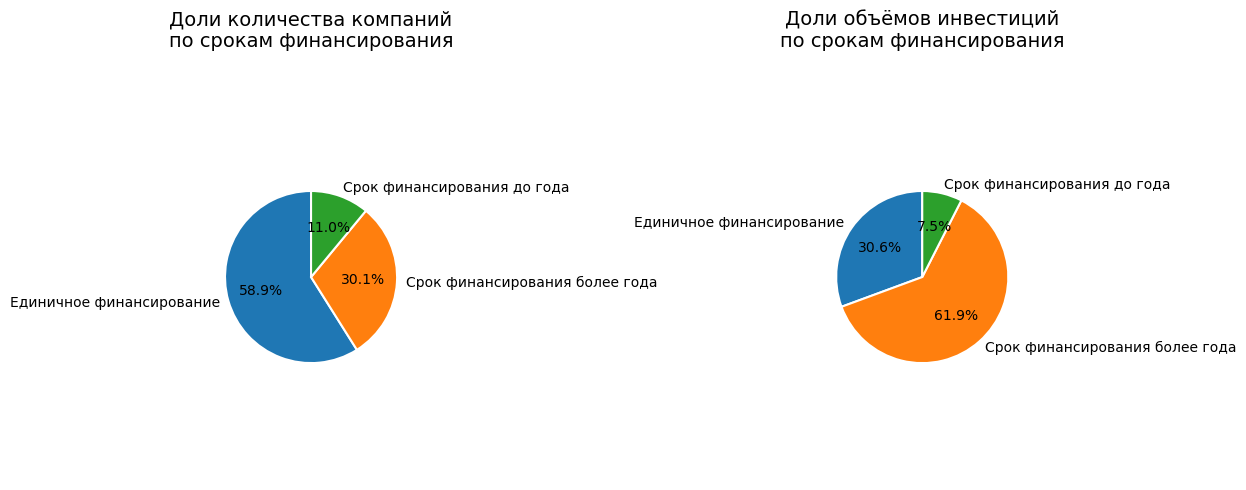

In [26]:
# Строим графики по долям компаний и объему финанасирования в разрезе категорий финансирования
fig, ax = plt.subplots(1, 2, figsize=(12, 5))

cols = [df['category_finance'].value_counts(), df.groupby('category_finance')['funding_total_usd'].sum()]
# Круг с количеством компаний по категориям
ax[0].pie(
    cols[0],
    labels=cols[0].index.tolist(),
    autopct='%1.1f%%',
    startangle=90,
    counterclock=True,
    wedgeprops={'edgecolor': 'white', 'linewidth': 1.5}
)

ax[0].axis('equal')
ax[0].set_title('Доли количества компаний\nпо срокам финансирования', fontsize=14, pad=20)


# Круг с объемом инвестиций по категориям
ax[1].pie(
    cols[1],
    labels=cols[1].index.tolist(),
    autopct='%1.1f%%',
    startangle=90,
    counterclock=True,
    wedgeprops={'edgecolor': 'white', 'linewidth': 1.5}
)

ax[1].axis('equal')
ax[1].set_title('Доли объёмов инвестиций\nпо срокам финансирования', fontsize=14, pad=20)


plt.tight_layout()

fname_base = "categ_finance_pie"
fname_png = f"{fname_base}.png"
fname_pdf = f"{fname_base}.pdf"

fig.savefig(png_dir / fname_png, dpi=300, bbox_inches="tight", pad_inches=0.1)
fig.savefig(pdf_dir / fname_pdf, bbox_inches="tight", pad_inches=0.1)

plt.show()

Для оценки структуры выборки построены две круговые диаграммы:

- слева — доли компаний по категориям сроков финансирования (на основе признака category_finance)

- справа — доли совокупного объёма финансирования по тем же категориям.

Разбивка по объёму получена агрегированием funding_total_usd в разрезе category_finance

#### Выводы по разделу «Группы по срокам финансирования»

Для классификации компаний по характеру финансирования рассчитана длительность периода между первым и последним раундами (`last_funding_at − first_funding_at`). На основе числа раундов (`funding_rounds`) и длительности периода все компании отнесены к одной из трёх групп:

- Единичное финансирование — единственный раунд;
- Срок финансирования до года — несколько раундов, интервал между крайними ≤ 365 дней;
- Срок финансирования более года — несколько раундов, интервал > 365 дней.

Построены две круговые диаграммы: по количеству компаний и по объёму привлечённых инвестиций.

Распределение по количеству компаний. В выборке ожидаемо преобладают компании с единственным раундом финансирования — на них приходится почти 59 % всех проектов. Компании с длительным периодом финансирования (более года) составляют около 30 %, а с коротким (до года) — лишь 11 %. То есть среди стартапов, привлёкших средства более одного раза, большинство проходит несколько раундов на протяжении длительного времени, а не в течение одного года.

Распределение по объёму инвестиций. Картина принципиально иная. На компании с длительным периодом финансирования приходится 61,9 % всего объёма привлечённых средств — это наибольшая доля. Единичное финансирование аккумулирует лишь 30,6 % средств, а сегмент «до года» — минимальные 7,5 %.

[Вернуться к разделу «Инжиниринг признаков»](#data_engeneer)

[Вернуться в начало](#beginning)

<a id='data_engeneer_task_2'></a>

### Выделение средних и нишевых сегментов рынка

Компании указывают свой сегмент рынка в столбце `market`. Рассчитайте, как часто в датасете встречается каждый из сегментов. 
Сегменты, к которым относится более 120 компаний, отнесите к массовым, сегменты, в которые входит от 35 до 120 включительно, отнесите к средним, а сегменты до 35 компаний отнесите к нишевым. Рассчитайте, сколько сегментов попадает в каждую из категорий.

Постройте график распределения количества компаний в сегментах и отобразите на нём разделение на нишевые и средние сегменты.

Оставьте в столбце `market` только массовые сегменты. Для остальных сегментов замените значения на заглушки — **niche** для нишевых и **mid** для средних.

Дальнейшие исследования выполняйте с учётом этой замены. Индивидуальные сегменты внутри средней и нишевой групп рассматривать не нужно — они объединяются в два общих сегмента.

In [27]:
# Выведим список уникальных значений сегментов
list(df['market'].unique())[:30]

[' Education ',
 nan,
 ' Business Services ',
 ' Social Media ',
 ' Hardware + Software ',
 ' Biotechnology ',
 ' Hardware + Software',
 ' Hospitality ',
 ' Enterprise Software ',
 ' Manufacturing ',
 'Finance',
 ' Finance ',
 ' Design ',
 ' Utilities ',
 ' Nonprofits ',
 ' Software ',
 ' Curated Web ',
 ' Health Care ',
 ' Education',
 ' Pharmaceuticals ',
 ' Health and Wellness ',
 ' Media ',
 ' Politics ',
 ' Clean Technology ',
 'Manufacturing',
 ' Financial Services ',
 ' Consumer Electronics ',
 ' Web Hosting ',
 'E-Commerce',
 ' Automotive ']

In [28]:
# Заменяем пропуски на 'Unknown'
#df['market'] = df['market'].fillna('Unknown')

In [29]:
# Фильтруем компании с неизвестной отраслью деятельности
df = df[df['market'].notna()]

In [30]:
# Выведим количество уникальных сегментов
df['market'].nunique()

848

In [31]:
# Удалим лишние пробелы в названиях сегментов
df['market'] = df['market'].str.strip()

# # Выведим количество уникальных сегментов после предобработки
df['market'].nunique()

394

In [32]:
# Считаем количество компаний в каждом сегменте
market_cnt = df['market'].value_counts()

# Категоризация сегментов
def categ_market(count):
    if count > 120:
        return 'массовый'
    elif 35 <= count <= 120:
        return 'средний'
    else:
        return 'нишевый'

market_cat = market_cnt.apply(categ_market)

path_file = interim_dir / 'market_cat.csv'
market_cat.to_csv(path_file)

# Выводим количество сегментов в каждой категории
category_counts = market_cat.value_counts()
display(category_counts)

category_frac = market_cat.value_counts(normalize=True)
display(category_frac)

# Выводим таблицу с сегментами, количеством компаний и категориями
market_total = pd.DataFrame({
    'count': market_cnt,
    'category': market_cat
}).reset_index().rename(columns={'index': 'market'})

path_file = interim_dir / 'market_total.csv'
market_total.to_csv(path_file)

display(market_total)


нишевый     289
средний      57
массовый     48
Name: market, dtype: int64

нишевый     0.733503
средний     0.144670
массовый    0.121827
Name: market, dtype: float64

,market,count,category
0,Software,4812,массовый
1,Biotechnology,3590,массовый
2,Mobile,2344,массовый
3,E-Commerce,1866,массовый
4,Curated Web,1693,массовый
...,...,...,...
389,Chat,1,нишевый
390,iPad,1,нишевый
391,Gadget,1,нишевый
392,Data Center Automation,1,нишевый


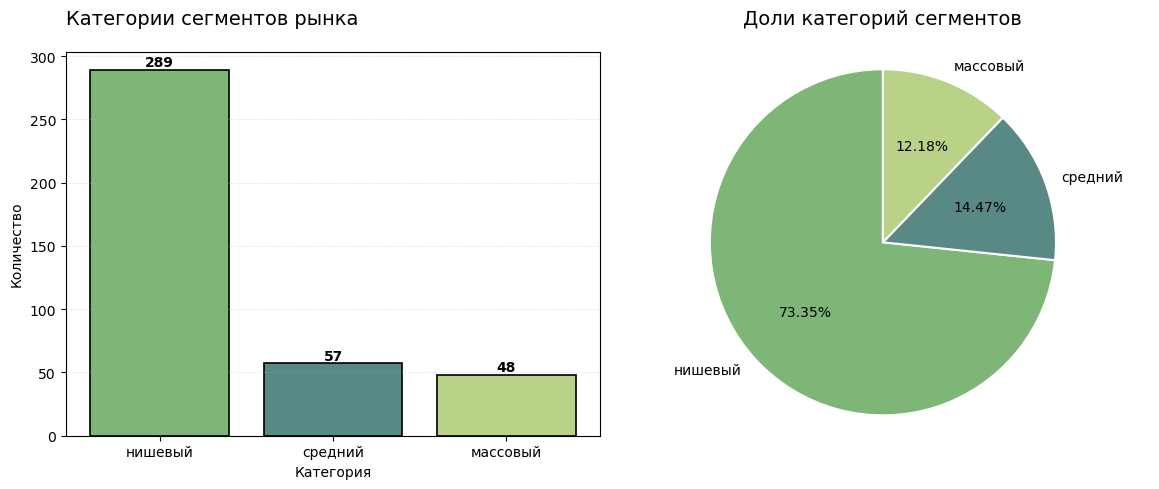

In [33]:
# Построим круговые диаграммы для количества и доли сегментов в каждой диаграмме

colors_02 = ['#7DB677', '#598985', '#BAD188']
cats = category_counts.index.tolist()
color_map = {cat: colors_02[i % len(colors_02)] for i, cat in enumerate(cats)}
bar_colors = [color_map[cat] for cat in cats]
pie_colors = bar_colors

fig, ax = plt.subplots(1, 2, figsize=(12, 5))

cols = [category_counts, category_frac]
# Столбчатая диаграмма с количеством сегментов по категориям
ax[0].bar(
    x=category_counts.index.tolist(),
    height=category_counts.values,
    color=bar_colors,
    edgecolor='black',
    linewidth=1.2
)

# Добавим подписи со значениями на столбцы
for i, val in enumerate(category_counts.values):
    ax[0].text(
        i, val + 0.5,
        f'{val:.0f}',
        ha='center',
        va='bottom',
        fontsize=10,
        fontweight='bold'
    )

ax[0].set_title('Категории сегментов рынка', loc='left', fontsize=14, pad=20)
ax[0].set_xlabel('Категория')
ax[0].set_ylabel('Количество')
ax[0].tick_params(axis='x')
ax[0].grid(axis='y', linestyle=':', alpha=0.4)


# Круг с долями сегментов по категориям
ax[1].pie(
    cols[1],
    labels=cols[1].index.tolist(),
    autopct='%1.2f%%',
    startangle=90,
    counterclock=True,
    wedgeprops={'edgecolor': 'white', 'linewidth': 1.5},
    colors=pie_colors
)

ax[1].axis('equal')
ax[1].set_title('Доли категорий сегментов', fontsize=14, pad=20)


plt.tight_layout()

fname_base = "categ_seg"
fname_png = f"{fname_base}.png"
fname_pdf = f"{fname_base}.pdf"

fig.savefig(png_dir / fname_png, dpi=300, bbox_inches="tight", pad_inches=0.1)
fig.savefig(pdf_dir / fname_pdf, bbox_inches="tight", pad_inches=0.1)

plt.show()

Построим график 'Распределение количества компаний в сегментах' с помощью логарифмической шкалы.

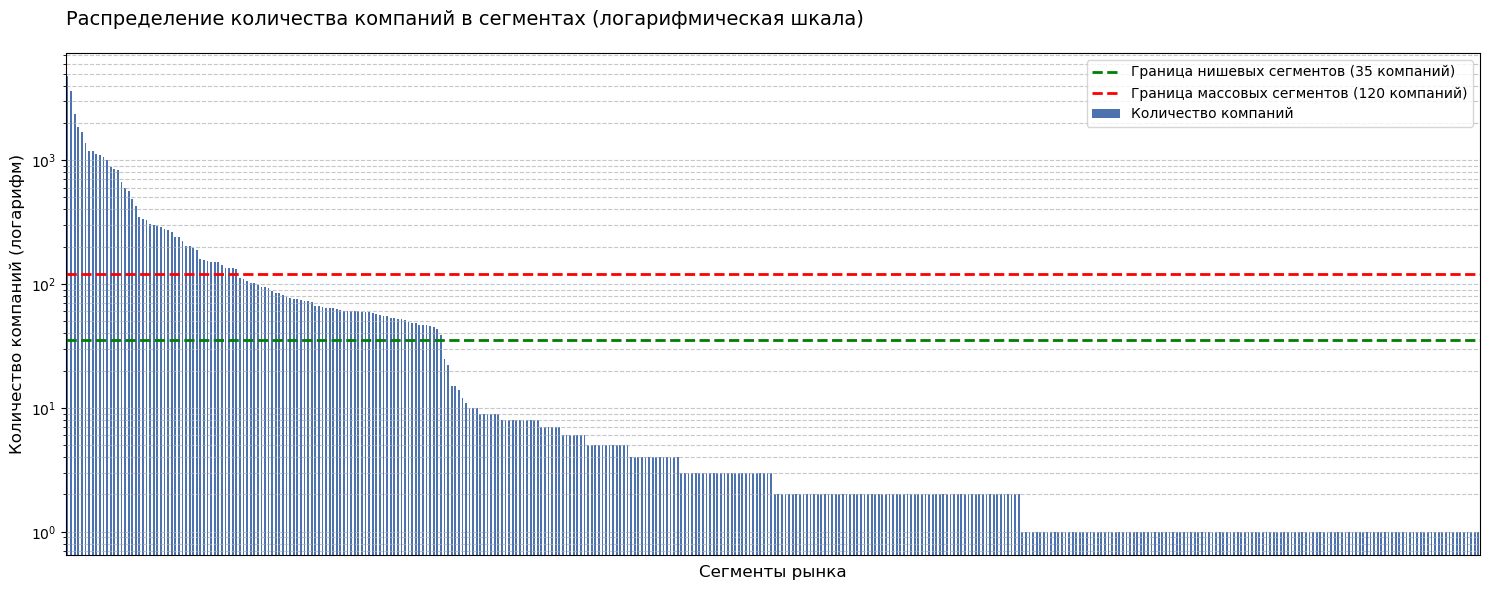

In [34]:
# Строим столбчатую диаграмму
fig, ax = plt.subplots(figsize=(15, 6))

market_total['count'].plot(
    kind='bar',
    ax=ax,
    color='#4c72b0',
    label='Количество компаний'
)

# Границы на лог‑шкале
ax.axhline(y=35, color='green', linestyle='--', linewidth=2,
           label='Граница нишевых сегментов (35 компаний)')
ax.axhline(y=120, color='red', linestyle='--', linewidth=2,
           label='Граница массовых сегментов (120 компаний)')

# Включаем логарифмическую шкалу по оси Y
ax.set_yscale('log')

# Подписи и оформление
ax.set_title('Распределение количества компаний в сегментах (логарифмическая шкала)',
             loc='left', fontsize=14, pad=20)
ax.set_xlabel('Сегменты рынка', fontsize=12)
ax.set_ylabel('Количество компаний (логарифм)', fontsize=12)


ax.set_xticks([])

ax.legend(loc='upper right')
ax.grid(axis='y', linestyle='--', alpha=0.7, which='both')  # both: major + minor

plt.tight_layout()

fname_base = "cnt_company_market_log"
fname_png = f"{fname_base}.png"
fname_pdf = f"{fname_base}.pdf"

fig.savefig(png_dir / fname_png, dpi=150, bbox_inches="tight", pad_inches=0.1)
fig.savefig(pdf_dir / fname_pdf, bbox_inches="tight", pad_inches=0.1)

plt.show()


Обоснования выбора графика с логарифмической шкалой.

Логарифмическая шкала раскрывает «хвост» распределения — мелкие сегменты (2–20 компаний) становятся читаемыми. Пороги 35 и 120 сохраняют смысл и лучше видны на фоне крупных сегментов. Порядок величин не меняется: сегмент с 10 компаниями по‑прежнему меньше сегмента с 100 — шкала просто делает различия между порядками величин нагляднее.

In [35]:
# Выделение сегментов рынка
def market_categories(df: pd.DataFrame, market_total: pd.DataFrame) -> pd.DataFrame:
    """
    Обогащает DataFrame данными о сегментах рынка и унифицирует категории рынка.
    
    Логика работы:
    1. Выполняет LEFT JOIN с таблицей market_total по колонке 'market' — чтобы подтянуть
       дополнительную статистику по сегментам (например, общее число компаний).
    2. Удаляет исходный столбец 'count' (если он конфликтует с новыми данными или избыточен).
    3. Перекодирует значения в колонке 'market' на основе категории ('массовый', 'средний', 'нишевый'):
       - для 'массовый' → сохраняет оригинальное название рынка (из df['market']),
       - для 'средний' → заменяет на метку 'mid',
       - для 'нишевый' → заменяет на метку 'niche'.
    4. Возвращает обновлённый DataFrame.
    
    Параметры
    ----------
    df : pd.DataFrame
        Исходный DataFrame с данными о компаниях и их категориях.
    market_total : pd.DataFrame
        Справочный DataFrame с агрегированными данными по рынкам (должен содержать колонку 'market').
    
    Возвращает
    -----------
    pd.DataFrame
        Обновлённый DataFrame с унифицированными метками рынков и подтянутыми данными.
    """
    # Объединяем данные по рынку (LEFT JOIN) — сохраняем все строки из df,
    # подтягивая статистику из market_tota
    df = df.merge(market_total, on='market', how='left')
    # удаляем старый столбец count, чтобы избежать путаницы с новыми данными
    df = df.drop(columns=['count'])

    # Задаём условия
    conditions = [
        df['category'] == 'массовый',
        df['category'] == 'средний',
        df['category'] == 'нишевый'
    ]
    # Задаём значения, которые будут присвоены при выполнении условий
    choices = [
        df['market'],
        'mid',
        'niche'
    ]
    # Применяем логику перекодировки через assign + np.select
    # np.select последовательно проверяет условия и присваивает первое подходящее значение из choices.
    # Если ни одно условие не выполнено (например, категория не распознана), ставится default='Unknown'
    df = df.assign(
            market=lambda x: np.select(conditions, choices, default='Unknown')
        )
    
    return df

df = market_categories(df, market_total)

path_file = processed_dir / 'df.csv'
df.to_csv(path_file)

df.head()

,name,homepage_url,category_list,market,funding_total_usd,status,country_code,state_code,region,city,...,round_a,round_b,round_c,round_d,round_e,round_f,round_g,round_h,category_finance,category
0,Harvard University,http://harvard.edu,|Education|,Education,90000000.0,operating,USA,MA,Boston,Cambridge,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Единичное финансирование,массовый
1,DuPont,http://www.dupont.com,|Business Services|Agriculture|Automotive|Inve...,mid,9000000.0,operating,USA,DE,"Wilmington, Delaware",Wilmington,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Единичное финансирование,средний
2,University of Michigan,http://www.umich.edu/,|Education|,Education,7700000.0,operating,USA,MI,Detroit,Ann Arbor,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Срок финансирования до года,массовый
3,Case Western Reserve University,http://www.case.edu,|Education|,Education,540000.0,operating,USA,OH,Cleveland,Cleveland,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Единичное финансирование,массовый
4,Tulane University,http://tulane.edu/,|Education|,Education,12000000.0,operating,USA,LA,New Orleans,New Orleans,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Срок финансирования до года,массовый


In [36]:
# Выводим обновленный столбец 'market'
df['market'].value_counts()

Software                4812
mid                     3841
Biotechnology           3590
Mobile                  2344
E-Commerce              1866
Curated Web             1693
Enterprise Software     1381
Health Care             1185
Clean Technology        1180
Games                   1117
Advertising             1107
Hardware + Software     1062
Social Media            1003
Health and Wellness      873
Education                844
niche                    830
Finance                  828
Analytics                667
Manufacturing            596
Security                 567
Semiconductors           484
Web Hosting              424
Consulting               349
Hospitality              336
Travel                   330
Fashion                  303
News                     301
Messaging                295
Search                   291
Real Estate              279
SaaS                     272
Music                    264
Internet                 241
Technology               238
Apps          

In [37]:
# Выводим количество компаний по категориям
df['category'].value_counts()

массовый    33733
средний      3841
нишевый       830
Name: category, dtype: int64

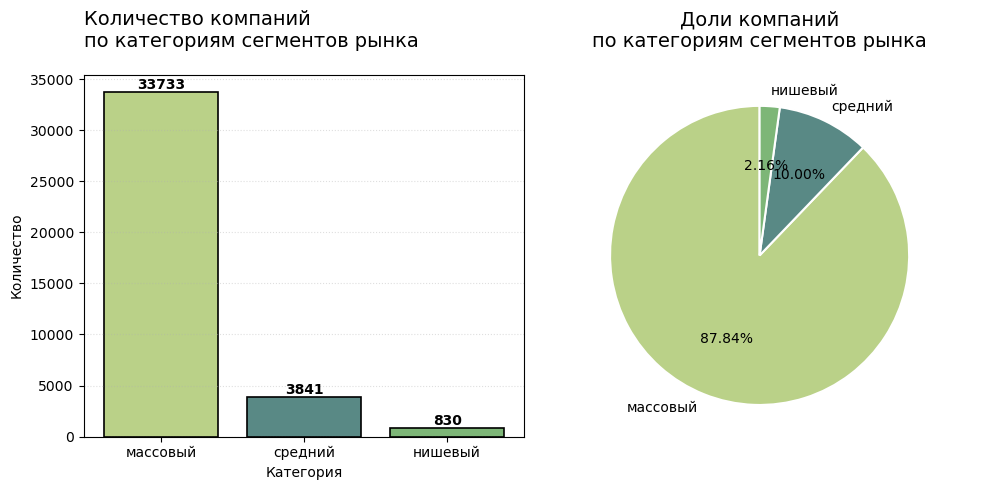

In [38]:
# Построим круговые диаграммы для количества и доли сегментов в каждой диаграмме

colors_02 = ['#BAD188', '#598985', '#7DB677']
cats = category_counts.index.tolist()
color_map = {cat: colors_02[i % len(colors_02)] for i, cat in enumerate(cats)}
bar_colors = [color_map[cat] for cat in cats]
pie_colors = bar_colors

fig, ax = plt.subplots(1, 2, figsize=(10, 5))

col = df['category'].value_counts().copy()
# Столбчатая диаграмма с количеством компаний по категориям
ax[0].bar(
    x=col.index.tolist(),
    height=col.values,
    color=bar_colors,
    edgecolor='black',
    linewidth=1.2
)

# Добавим подписи со значениями на столбцы
for i, val in enumerate(col):
    ax[0].text(
        i, val + 0.5,
        f'{val:.0f}',
        ha='center',
        va='bottom',
        fontsize=10,
        fontweight='bold'
    )

ax[0].set_title('Количество компаний\nпо категориям сегментов рынка', loc='left', fontsize=14, pad=20)
ax[0].set_xlabel('Категория')
ax[0].set_ylabel('Количество')
ax[0].tick_params(axis='x')
ax[0].grid(axis='y', linestyle=':', alpha=0.4)


# Круг с долями компаний по категориям
ax[1].pie(
    col,
    labels=col.index.tolist(),
    autopct='%1.2f%%',
    startangle=90,
    counterclock=True,
    wedgeprops={'edgecolor': 'white', 'linewidth': 1.5},
    colors=pie_colors
)

ax[1].axis('equal')
ax[1].set_title('Доли компаний\nпо категориям сегментов рынка', fontsize=14, pad=20)


plt.tight_layout()

fname_base = "categ_company"
fname_png = f"{fname_base}.png"
fname_pdf = f"{fname_base}.pdf"

fig.savefig(png_dir / fname_png, dpi=300, bbox_inches="tight", pad_inches=0.1)
fig.savefig(pdf_dir / fname_pdf, bbox_inches="tight", pad_inches=0.1)

plt.show()

#### Выводы по разделу «Выделение средних и нишевых сегментов рынка»

В ходе обработки столбца `market` выполнены следующие шаги:

1. Фильтрация. Строки с компаниями с отсутствующими значениями сегментов рынка были исключены (2503 строки).
2. Очистка названий. После удаления лишних пробелов по краям названий количество уникальных значений уменьшилось с 849 до 394. Это свидетельствует о том, что значительная часть «дубликатов» возникла из-за различий в написании (лишние пробелы в начале, конце или несколько пробелов подряд), а не из-за реально разных сегментов рынка.
3. Классификация сегментов. По количеству компаний сегменты разделены на три группы:
   - нишевые (до 35 компаний) — 289 сегментов;
   - средние (от 35 до 120 компаний включительно) — 57 сегментов;
   - массовые (более 120 компаний) — 49 сегментов.

Анализ частоты встречаемости показал, что распределение компаний по сегментам крайне неравномерно. Наибольшее количество компаний сосредоточено в сегментах `Software` (4 812), `Biotechnology` (3 590), `Mobile` (2 344) и `E-Commerce` (1 866).

Структура сегментов отражает высокую фрагментированность рынка стартапов: более 73 % всех сегментов являются нишевыми, около 14 % — средними и лишь порядка 12 % — массовыми. При этом основная доля компаний (свыше 88 %, то есть 33 733 из 38 404) сосредоточена всего в 48 массовых сегментах. Это подтверждает, что большинство стартапов работает в ограниченном числе популярных направлений, тогда как нишевые сегменты объединяют незначительное число проектов.

Для дальнейшего анализа индивидуальные средние и нишевые сегменты объединены в две обобщённые категории — `mid` (3 841 компания, ~10,0 %) и `niche` (830 компаний, ~2,2 %), тогда как 48 массовых сегментов сохранены без изменений (33 733 компании, ~87,8 %). Такое преобразование позволяет сократить число категорий и сфокусировать дальнейшее исследование на наиболее значимых направлениях рынка, не теряя при этом информации о нишевых и средних проектах.

[Вернуться к разделу «Инжиниринг признаков»](#data_engeneer)

[Вернуться в начало](#beginning)

<a id='data_engeneer_conc'></a>

### Общие выводы по разделу «Инжиниринг признаков»

В рамках инжиниринга признаков решены две прикладные задачи, формирующие основу для последующего анализа:

1. Классификация компаний по срокам финансирования. Создан признак `category_finance` с тремя категориями, отражающими характер финансирования компании. Показано, что численное большинство составляют компании с единственным раундом (~59 %), однако по объёму инвестиций лидирует сегмент с длительным периодом финансирования (> 1 года, ~62 %).

2. Сегментация рынка по популярности. Столбец `market` очищен от лишних пробелов (уникальных значений стало 395 вместо 849), строки с компаниями с отсутствующими значениями сегментов рынка были исключены (2503 строки), а сегменты классифицированы по числу компаний на массовые (> 120), средние (35–120) и нишевые (< 35). В результате:
   - массовые сегменты — 48 (12,2 % от числа сегментов), но в них сосредоточено 33 733 компаний (~87,8 %);
   - средние сегменты — 57 (14,5 %), 3 841 компания (~10,0 %);
   - нишевые сегменты — 289 (73,4 %), 830 компаний (~2,2 %).

   Индивидуальные средние и нишевые сегменты объединены в агрегированные категории `mid` и `niche`, массовые оставлены как есть. Это снижает размерность категориального признака и концентрирует последующий анализ на доминирующих направлениях рынка, сохраняя при этом информацию о нишевых и средних проектах в виде отдельных групп.

[Вернуться к разделу «Инжиниринг признаков»](#data_engeneer)

[Вернуться в начало](#beginning)

<a id='data_analys'></a>

## Работа с выбросами и анализ

1. [Анализируем и помечаем выбросы в каждом из сегментов](#analyz_exces_segments)
    - [Промежуточные выводы по разделу](#conc_analyz_exces_segments)
2. [Определяем границы рассматриваемого периода, отбрасываем аномалии](#borders_period)
    - [Промежуточные выводы по разделу](#conc_borders_period)
3. [Анализ типов финансирования по объёму и популярности](#analys_types_finance_total)
    - [Промежуточные выводы по разделу](#conc_analys_types_finance_total)

[Вернуться в начало](#beginning)

<a id='analyz_exces_segments'></a>

### Анализируем и помечаем выбросы в каждом из сегментов

Заказчика интересует обычный для рассматриваемого периода размер средств, который предоставлялся компаниям.

По предобработанному столбцу `funding_total_usd` графическим образом оцените, какой размер общего финансирования для одной компании будет типичным, а какой — выбивающимся. Укажите интервал, в котором лежат типичные значения.

Определите компании с аномальным объёмом общего финансирования — используйте метод IQR отдельно по каждому сегменту. Напомним, что все нишевые сегменты должны быть объединены в одну группу, а средние — в другую.

Определите сегменты рынка с наибольшей долей компаний, получивших аномальное финансирование, и выведите топ таких сегментов.

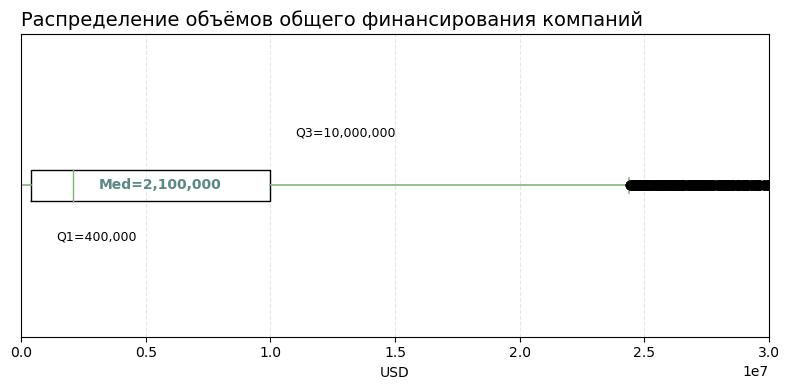

In [39]:
# Построим график размаха для столбца 'funding_total_usd'
fig, ax = plt.subplots(1, 1, figsize=(8, 4))

bp = ax.boxplot(
    df['funding_total_usd'],
    vert=False,
    widths=0.1,
    medianprops={'color': '#7DB677', 'linewidth': 1},
    whiskerprops={'color': '#7DB677', 'linewidth': 1.2},
    capprops={'color': '#7DB677', 'linewidth': 1.2}
)

ax.set_title('Распределение объёмов общего финансирования компаний', loc='left', fontsize=14)
ax.set_xlabel('USD')
ax.set_xlim(0, 30_000_000)
ax.grid(axis='x', alpha=0.3, linestyle='--')
ax.set_yticks([])

# Считаем статистики
med = df['funding_total_usd'].median()
q1 = df['funding_total_usd'].quantile(0.25)
q3 = df['funding_total_usd'].quantile(0.75)

y_pos = 1 # Строка для подписи статистик

offset = 1_000_000  # отступ в USD

ax.text(med + offset, y_pos, f'Med={med:,.0f}',
        va='center', ha='left', fontsize=10, color='#598985', fontweight='bold')

ax.text(q1 + offset, y_pos - 0.15, f'Q1={q1:,.0f}',
        va='top', ha='left', fontsize=9, color='black')

ax.text(q3 + offset, y_pos + 0.15, f'Q3={q3:,.0f}',
        va='bottom', ha='left', fontsize=9, color='black')

plt.tight_layout()

fname_base = "funding_total_usd_boxplot"
fname_png = f"{fname_base}.png"
fname_pdf = f"{fname_base}.pdf"

fig.savefig(png_dir / fname_png, dpi=150, bbox_inches="tight", pad_inches=0.1)
fig.savefig(pdf_dir / fname_pdf, bbox_inches="tight", pad_inches=0.1)

plt.show()

In [40]:
# Определяем границы аномалий
# Межквартильный размах
q1 = df['funding_total_usd'].quantile(0.25)
q3 = df['funding_total_usd'].quantile(0.75)
iqr = q3 - q1

# Границы
lower_bord = max(0, q1 - 1.5 * iqr)
upper_bord = q3 + 1.5 * iqr

display(
    f'Диапазон финансирования без аномалий: '
    f'от {lower_bord:,.0f} до {upper_bord:,.0f} USD'
    .replace(',', ' ')
)

'Диапазон финансирования без аномалий: от 0 до 24 400 000 USD'

In [41]:
# Вычислим верхнюю границу для каждого сегмента
def iqr_border(series):
    # Межквартильный размах
    q1 = series.quantile(0.25)
    q3 = series.quantile(0.75)
    iqr = q3 - q1
    return q3 + 1.5 * iqr

borders = df.groupby('market')['funding_total_usd'].apply(iqr_border)
borders.name = 'upper_bord'
borders.to_frame()
borders

market
Advertising             2.711250e+07
Analytics               2.694795e+07
Apps                    5.273938e+06
Automotive              2.460245e+07
Big Data                1.705000e+07
Biotechnology           5.282918e+07
Clean Technology        6.824155e+07
Cloud Computing         2.412204e+07
Consulting              1.313750e+07
Curated Web             1.157500e+07
Design                  1.251000e+07
E-Commerce              1.580500e+07
Education               1.182108e+07
Enterprise Software     3.600000e+07
Entertainment           1.912809e+07
Fashion                 1.974472e+07
Finance                 3.288675e+07
Games                   1.972500e+07
Hardware + Software     2.679238e+07
Health Care             6.737500e+07
Health and Wellness     1.888990e+07
Hospitality             1.726250e+07
Internet                1.212500e+07
Manufacturing           3.305388e+07
Marketplaces            4.960428e+06
Medical                 2.477500e+07
Messaging               1.83297

In [42]:
# Объединим таблицы
df = df.merge(borders,
         how='left',
         on='market')

In [43]:
# Уменьшим разрядность столбцов с миллионами USD
df[['funding_total_usd', 'upper_bord']] = df[['funding_total_usd', 'upper_bord']] / 1000000
df.head()

,name,homepage_url,category_list,market,funding_total_usd,status,country_code,state_code,region,city,...,round_b,round_c,round_d,round_e,round_f,round_g,round_h,category_finance,category,upper_bord
0,Harvard University,http://harvard.edu,|Education|,Education,90.00,operating,USA,MA,Boston,Cambridge,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Единичное финансирование,массовый,11.821079
1,DuPont,http://www.dupont.com,|Business Services|Agriculture|Automotive|Inve...,mid,9.00,operating,USA,DE,"Wilmington, Delaware",Wilmington,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Единичное финансирование,средний,19.250000
2,University of Michigan,http://www.umich.edu/,|Education|,Education,7.70,operating,USA,MI,Detroit,Ann Arbor,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Срок финансирования до года,массовый,11.821079
3,Case Western Reserve University,http://www.case.edu,|Education|,Education,0.54,operating,USA,OH,Cleveland,Cleveland,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Единичное финансирование,массовый,11.821079
4,Tulane University,http://tulane.edu/,|Education|,Education,12.00,operating,USA,LA,New Orleans,New Orleans,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Срок финансирования до года,массовый,11.821079


In [44]:
# Создадим столбец с меткой компанией, у которой значение общего финансирования выше типичного по сегменту (True - превышение)
df['is_excess'] = df['funding_total_usd'] > df['upper_bord']
df.head()

,name,homepage_url,category_list,market,funding_total_usd,status,country_code,state_code,region,city,...,round_c,round_d,round_e,round_f,round_g,round_h,category_finance,category,upper_bord,is_excess
0,Harvard University,http://harvard.edu,|Education|,Education,90.00,operating,USA,MA,Boston,Cambridge,...,0.0,0.0,0.0,0.0,0.0,0.0,Единичное финансирование,массовый,11.821079,True
1,DuPont,http://www.dupont.com,|Business Services|Agriculture|Automotive|Inve...,mid,9.00,operating,USA,DE,"Wilmington, Delaware",Wilmington,...,0.0,0.0,0.0,0.0,0.0,0.0,Единичное финансирование,средний,19.250000,False
2,University of Michigan,http://www.umich.edu/,|Education|,Education,7.70,operating,USA,MI,Detroit,Ann Arbor,...,0.0,0.0,0.0,0.0,0.0,0.0,Срок финансирования до года,массовый,11.821079,False
3,Case Western Reserve University,http://www.case.edu,|Education|,Education,0.54,operating,USA,OH,Cleveland,Cleveland,...,0.0,0.0,0.0,0.0,0.0,0.0,Единичное финансирование,массовый,11.821079,False
4,Tulane University,http://tulane.edu/,|Education|,Education,12.00,operating,USA,LA,New Orleans,New Orleans,...,0.0,0.0,0.0,0.0,0.0,0.0,Срок финансирования до года,массовый,11.821079,True


In [45]:
# Определим ТОП-10 сегментов по количеству компаний с аномальным финансированием
exc_fun = df.groupby('market')['is_excess'].mean().sort_values(ascending=False)

In [46]:
# Агрегации по рынку
agg = (
    df.groupby('market', dropna=False)
      .agg(
          total_companies=('name', 'count'),
          companies_with_excess=('is_excess', 'sum'),
          share_excess=('is_excess', 'mean')
      )
)

# Переводим долю в проценты и округляем
agg['share_excess_pct'] = round(agg['share_excess'] * 100, 2)

report_exc = agg.rename(columns={
    'total_companies': 'Всего компаний',
    'companies_with_excess': 'Компании с аномальным финансированием',
    'share_excess': 'Доля компаний',
    'share_excess_pct': 'Доля компаний (%)'
})

# Сортируем и отбираем ТОП-10
report_exc_top = (
    report_exc
    .sort_values('Доля компаний (%)', ascending=False)
    .head(10)
)

display(
    report_exc_top.style
        .set_caption('Статистика по компаниям с аномальным финансированием')
        .format({'Доля компаний (%)': '{:.2f}%'})
        .bar(subset=['Доля компаний'], color='#d6eaf8')
        .background_gradient(subset=['Доля компаний (%)'], cmap='coolwarm')
)

,Всего компаний,Компании с аномальным финансированием,Доля компаний,Доля компаний (%)
market,,,,
Real Estate,279,48,0.172043,17.20%
Entertainment,150,25,0.166667,16.67%
Consulting,349,58,0.166189,16.62%
Search,291,48,0.164948,16.49%
Cloud Computing,152,25,0.164474,16.45%
Photography,204,33,0.161765,16.18%
SaaS,272,44,0.161765,16.18%
Technology,238,38,0.159664,15.97%
Video,188,30,0.159574,15.96%


<a id='conc_analyz_exces_segments'></a>

#### Промежуточные выводы по разделу «Анализируем и помечаем выбросы в каждом из сегментов»

Анализ распределения общего объёма финансирования по всей выборке показал, что значения сильно смещены вправо: медиана составляет около 2 млн долларов, первый квартиль (Q1) — 0, третий квартиль (Q3) — 10 млн, тогда как максимальные значения достигают сотен миллионов и даже миллиардов долларов. Такая форма распределения типична для венчурного рынка, где единичные крупные сделки формируют значительную часть общего объёма инвестиций, а большинство компаний привлекает относительно скромные суммы.

Для выявления аномалий был применён метод межквартильного размаха (IQR). По всей выборке типичный объём финансирования укладывается в диапазон от 0 до ~24,5 млн долларов; значения выше этой границы можно рассматривать как аномальные.

Поскольку разные сегменты рынка имеют различный уровень инвестиционной активности, определение выбросов проводилось отдельно внутри каждого сегмента. Средние и нишевые направления были предварительно объединены в группы `mid` и `niche`, что позволило сделать сравнение более корректным. В результате верхняя граница IQR для группы `mid` составила ~19,3 млн долларов, для группы `niche` — ~13,2 млн, тогда как для массовых сегментов значения верхней границы варьируются от ~5,4 млн (`Startups`) до ~75 млн (`Semiconductors`).

По итогам расчёта создан признак `is_excess`, помечающий компании, у которых объём общего финансирования превышает верхнюю границу IQR своего сегмента (`True` — превышение). Признак сохранён в датафрейме для дальнейшего анализа.

Наибольшая доля компаний с высоким для своего сегмента объёмом финансирования наблюдается в сегментах:

- Real Estate — 48 из 279 компаний (17,2 %);
- Entertainment — 25 из 150 (16,7 %);
- Consulting — 58 из 349 (16,6 %);
- Search — 48 из 291 (16,5 %);
- Cloud Computing — 25 из 152 (16,4 %).

Далее следуют Photography (16,2 %), SaaS (16,2 %), Technology (16,0 %) и Video (16,0 %), а также агрегированная группа `niche` (15,9 %, 132 из 830 компаний).

Анализ выбросов проводился внутри каждого сегмента с помощью метода межквартильного размаха (IQR).

При правосторонне асимметричном распределении доля выбросов около 15 % наблюдений — это ожидаемый эффект.

В топ‑сегментах по доле аномальных значений (Real Estate, Entertainment, Consulting и др.) доля колеблется в узком диапазоне 15,9–17,2 %. Такой небольшой разброс говорит о схожем характере распределения финансирования в этих сегментах.

Выбросы были сохранены в выборке для дальнейшего анализа, поскольку они отражают реальные крупные инвестиционные сделки и могут быть важны при оценке привлекательности отдельных направлений рынка. При необходимости их можно исключить или проанализировать отдельно с помощью созданного признака `is_excess`.

[Вернуться к разделу «Работа с выбросами и анализ»](#data_analys)

[Вернуться в начало](#beginning)

<a id='borders_period'></a>

### Определяем границы рассматриваемого периода, отбрасываем аномалии

Проверьте по датасету, можно ли считать, что вам предоставили полные данные за 2014 год. Затем исключите из датасета компании, которые вы ранее посчитали получившими аномальное финансирование.

Когда исключите аномальные записи, на основе столбцов mid_funding_at и funding_rounds оставьте в датасете данные только об определённых компаниях. Они должны были получать финансирование в годы, когда было зафиксировано 50 или более раундов финансирования.

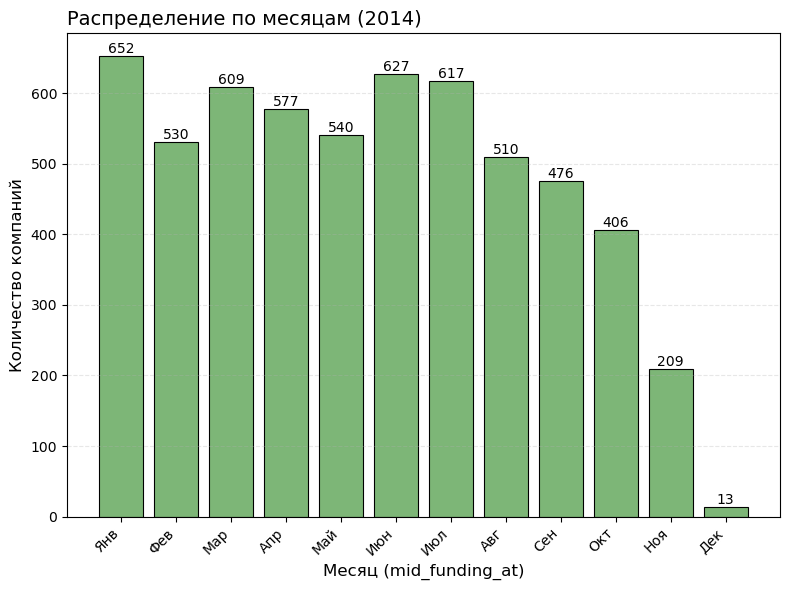

In [47]:
# Построим график по количеству компаний за 2014 год по месяцам
df_month_2014 = df.loc[df['mid_funding_at'].dt.year == 2014, 'mid_funding_at'].dt.month.copy()
md = df_month_2014.value_counts().sort_index()

fig, ax = plt.subplots(figsize=(8, 6))
bars = ax.bar(
    md.index,
    md.values,
    color='#7DB677', 
    edgecolor='black', 
    linewidth=0.8
)

ax.set_title('Распределение по месяцам (2014)', loc='left', fontsize=14)
ax.set_xlabel('Месяц (mid_funding_at)', fontsize=12)
ax.set_ylabel('Количество компаний', fontsize=12)

month_names = ['Янв', 'Фев', 'Мар', 'Апр', 'Май', 'Июн',
               'Июл', 'Авг', 'Сен', 'Окт', 'Ноя', 'Дек']
ax.set_xticks(range(1, len(md) + 1))
ax.set_xticklabels(
    [month_names[int(m) - 1] for m in md.index],
    rotation=45,
    ha='right'
)

for bar in bars:
    h = bar.get_height()
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        h,
        f'{int(h)}',
        ha='center',
        va='bottom',
        fontsize=10
    )

ax.grid(axis='y', linestyle='--', alpha=0.3)
plt.tight_layout()

fname_base = "month_2014_bar"
fname_png = f"{fname_base}.png"
fname_pdf = f"{fname_base}.pdf"

fig.savefig(png_dir / fname_png, dpi=150, bbox_inches="tight", pad_inches=0.1)
fig.savefig(pdf_dir / fname_pdf, bbox_inches="tight", pad_inches=0.1)

plt.show()

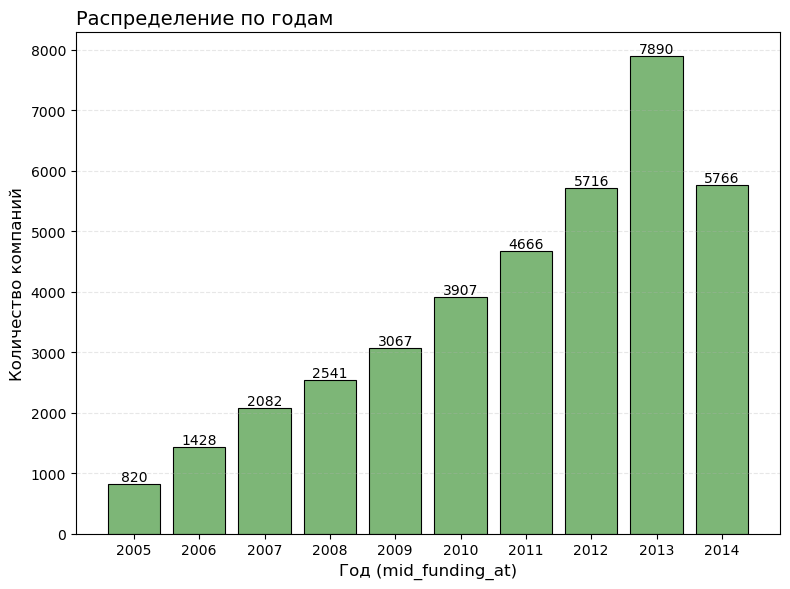

In [48]:
# Построим график по количеству компаний по годам
df_year = df['mid_funding_at'].dt.year.copy()
yd = df_year.value_counts().sort_index(ascending=False).head(10).sort_index()

fig, ax = plt.subplots(figsize=(8, 6))
bars = ax.bar(
    yd.index,
    yd.values,
    color='#7DB677', 
    edgecolor='black', 
    linewidth=0.8
)

ax.set_title('Распределение по годам', loc='left', fontsize=14)
ax.set_xlabel('Год (mid_funding_at)', fontsize=12)
ax.set_ylabel('Количество компаний', fontsize=12)
ax.set_xticks(yd.index)
ax.set_xticklabels(yd.index.astype(int).astype(str))

for bar in bars:
    h = bar.get_height()
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        h,
        f'{int(h)}',
        ha='center',
        va='bottom',
        fontsize=10
    )

ax.grid(axis='y', linestyle='--', alpha=0.3)
plt.tight_layout()

fname_base = "year_bar"
fname_png = f"{fname_base}.png"
fname_pdf = f"{fname_base}.pdf"

fig.savefig(png_dir / fname_png, dpi=150, bbox_inches="tight", pad_inches=0.1)
fig.savefig(pdf_dir / fname_pdf, bbox_inches="tight", pad_inches=0.1)

plt.show()

Данные за 2014 год, вероятнее всего, неполные, особенно за последние месяцы.

На месячном графике видно резкое сокращение числа компаний к концу года: если с января по октябрь показатель составляет от 497 до 740, то в ноябре он снижается до 306, а в декабре — до 23. Такое падение может указывать на то, что выгрузка была сформирована до завершения декабря либо сведения за последние месяцы ещё не успели поступить в базу.

На годовом графике также наблюдается снижение: с 8 423 компаний в 2013 году до 6 619 в 2014 году после продолжительного роста.

In [49]:
# Выведим первые 5 строк датафрейма df для проверки
df.head()

,name,homepage_url,category_list,market,funding_total_usd,status,country_code,state_code,region,city,...,round_c,round_d,round_e,round_f,round_g,round_h,category_finance,category,upper_bord,is_excess
0,Harvard University,http://harvard.edu,|Education|,Education,90.00,operating,USA,MA,Boston,Cambridge,...,0.0,0.0,0.0,0.0,0.0,0.0,Единичное финансирование,массовый,11.821079,True
1,DuPont,http://www.dupont.com,|Business Services|Agriculture|Automotive|Inve...,mid,9.00,operating,USA,DE,"Wilmington, Delaware",Wilmington,...,0.0,0.0,0.0,0.0,0.0,0.0,Единичное финансирование,средний,19.250000,False
2,University of Michigan,http://www.umich.edu/,|Education|,Education,7.70,operating,USA,MI,Detroit,Ann Arbor,...,0.0,0.0,0.0,0.0,0.0,0.0,Срок финансирования до года,массовый,11.821079,False
3,Case Western Reserve University,http://www.case.edu,|Education|,Education,0.54,operating,USA,OH,Cleveland,Cleveland,...,0.0,0.0,0.0,0.0,0.0,0.0,Единичное финансирование,массовый,11.821079,False
4,Tulane University,http://tulane.edu/,|Education|,Education,12.00,operating,USA,LA,New Orleans,New Orleans,...,0.0,0.0,0.0,0.0,0.0,0.0,Срок финансирования до года,массовый,11.821079,True


In [50]:
# Создадим для удаленных данных датафрейм
df_anomaly = df.query('is_excess == True').copy()

path_file = interim_dir / 'df_anomaly.csv'
df_anomaly.to_csv(path_file)

df_anomaly.head()

,name,homepage_url,category_list,market,funding_total_usd,status,country_code,state_code,region,city,...,round_c,round_d,round_e,round_f,round_g,round_h,category_finance,category,upper_bord,is_excess
0,Harvard University,http://harvard.edu,|Education|,Education,90.0,operating,USA,MA,Boston,Cambridge,...,0.0,0.0,0.0,0.0,0.0,0.0,Единичное финансирование,массовый,11.821079,True
4,Tulane University,http://tulane.edu/,|Education|,Education,12.0,operating,USA,LA,New Orleans,New Orleans,...,0.0,0.0,0.0,0.0,0.0,0.0,Срок финансирования до года,массовый,11.821079,True
7,VideoSurf,http://www.videosurf.com,|Hardware + Software|,Hardware + Software,28.0,acquired,USA,CA,SF Bay Area,San Mateo,...,0.0,0.0,0.0,0.0,0.0,0.0,Единичное финансирование,массовый,26.792376,True
11,University of Maryland,http://umd.edu,|Education|,Education,750.5,operating,USA,MD,"Washington, D.C.",College Park,...,0.0,0.0,0.0,0.0,0.0,0.0,Срок финансирования до года,массовый,11.821079,True
12,Great Atlantic & Pacific Tea,http://aptea.com,|Hospitality|,Hospitality,175.0,operating,USA,NJ,Newark,Montvale,...,0.0,0.0,0.0,0.0,0.0,0.0,Единичное финансирование,массовый,17.262500,True


In [51]:
# Исключим из датасета данные с аномальным финансированием
df = df.query('is_excess == False')

path_file = processed_dir / 'df.csv'
df.to_csv(path_file)

df.head()

,name,homepage_url,category_list,market,funding_total_usd,status,country_code,state_code,region,city,...,round_c,round_d,round_e,round_f,round_g,round_h,category_finance,category,upper_bord,is_excess
1,DuPont,http://www.dupont.com,|Business Services|Agriculture|Automotive|Inve...,mid,9.00,operating,USA,DE,"Wilmington, Delaware",Wilmington,...,0.0,0.0,0.0,0.0,0.0,0.0,Единичное финансирование,средний,19.250000,False
2,University of Michigan,http://www.umich.edu/,|Education|,Education,7.70,operating,USA,MI,Detroit,Ann Arbor,...,0.0,0.0,0.0,0.0,0.0,0.0,Срок финансирования до года,массовый,11.821079,False
3,Case Western Reserve University,http://www.case.edu,|Education|,Education,0.54,operating,USA,OH,Cleveland,Cleveland,...,0.0,0.0,0.0,0.0,0.0,0.0,Единичное финансирование,массовый,11.821079,False
5,Duke University,http://www.duke.edu,|Education|,Education,8.70,operating,USA,NC,Raleigh,Durham,...,0.0,0.0,0.0,0.0,0.0,0.0,Единичное финансирование,массовый,11.821079,False
6,WeGame,http://www.WeGame.com,|Social Media|,Social Media,3.50,acquired,USA,CA,SF Bay Area,San Francisco,...,0.0,0.0,0.0,0.0,0.0,0.0,Срок финансирования до года,массовый,7.312500,False


Отфильтруем датафрейм по количеству райндов финасирования

In [52]:
# Посчитаем количество раундов финансирования по годам
df['funding_year'] = df['mid_funding_at'].dt.year
rounds_fund_cnt_year = df.groupby('funding_year')['funding_rounds'].sum()
rounds_fund_cnt_year.name = 'funding_year_cnt'
rounds_fund_cnt_year.to_frame()
rounds_fund_cnt_year

funding_year
1960.0        2.0
1979.0        1.0
1984.0        2.0
1987.0        1.0
1989.0        1.0
1990.0        1.0
1992.0        2.0
1993.0        1.0
1994.0        3.0
1995.0        9.0
1996.0        8.0
1997.0        5.0
1998.0       15.0
1999.0       41.0
2000.0      109.0
2001.0       58.0
2002.0       97.0
2003.0      120.0
2004.0      169.0
2005.0      931.0
2006.0     1825.0
2007.0     2820.0
2008.0     3624.0
2009.0     4472.0
2010.0     5975.0
2011.0     7368.0
2012.0     9312.0
2013.0    12320.0
2014.0     6343.0
Name: funding_year_cnt, dtype: float64

In [53]:
# Объединим данные
df = df.merge(rounds_fund_cnt_year, on='funding_year', how='left')

# Создадим датафрейм с удаленным данными по количеству раундов финансирования
df_rounds_del = df.query('funding_year_cnt < 50').copy()

path_file = interim_dir / 'df_rounds_del.csv'
df_rounds_del.to_csv(path_file)

# Удалим из датафрейма df данные по количеству раундов финансирования
df = df.query('funding_year_cnt >= 50')

path_file = processed_dir / 'df.csv'
df.to_csv(path_file)

df.head()

,name,homepage_url,category_list,market,funding_total_usd,status,country_code,state_code,region,city,...,round_e,round_f,round_g,round_h,category_finance,category,upper_bord,is_excess,funding_year,funding_year_cnt
0,DuPont,http://www.dupont.com,|Business Services|Agriculture|Automotive|Inve...,mid,9.00,operating,USA,DE,"Wilmington, Delaware",Wilmington,...,0.0,0.0,0.0,0.0,Единичное финансирование,средний,19.250000,False,2009.0,4472.0
1,University of Michigan,http://www.umich.edu/,|Education|,Education,7.70,operating,USA,MI,Detroit,Ann Arbor,...,0.0,0.0,0.0,0.0,Срок финансирования до года,массовый,11.821079,False,2013.0,12320.0
2,Case Western Reserve University,http://www.case.edu,|Education|,Education,0.54,operating,USA,OH,Cleveland,Cleveland,...,0.0,0.0,0.0,0.0,Единичное финансирование,массовый,11.821079,False,2014.0,6343.0
3,Duke University,http://www.duke.edu,|Education|,Education,8.70,operating,USA,NC,Raleigh,Durham,...,0.0,0.0,0.0,0.0,Единичное финансирование,массовый,11.821079,False,2014.0,6343.0
4,WeGame,http://www.WeGame.com,|Social Media|,Social Media,3.50,acquired,USA,CA,SF Bay Area,San Francisco,...,0.0,0.0,0.0,0.0,Срок финансирования до года,массовый,7.312500,False,2007.0,2820.0


<a id='conc_borders_period'></a>

#### Промежуточные выводы по разделу «Определяем границы рассматриваемого периода, отбрасываем аномалии»

В ходе раздела выполнены три последовательных шага: проверка полноты данных за 2014 год, исключение компаний с аномальным для своего сегмента объёмом финансирования и ограничение периода исследования годами, в которых было зафиксировано достаточное число раундов финансирования.

1. Полнота данных за 2014 год.
Проверка по месяцам показала, что данные за 2014 год нельзя считать полными. На месячном графике число компаний с финансированием держится на уровне 497–740 в январе–октябре, затем снижается до 306 в ноябре и до 23 в декабре (график строился по столбцу `mid_funding_at`). Столь резкое падение в конце года не выглядит естественным и, вероятнее всего, связано с тем, что выгрузка была сформирована до завершения декабря либо данные за последние месяцы ещё не поступили в базу.

На годовом графике это также отражается: после устойчивого роста числа компаний до 8 423 в 2013 году в 2014 году зафиксировано 6 619 компаний. Такое снижение может быть следствием неполноты данных за 2014 год, поэтому годовые итоги 2014 года следует интерпретировать с осторожностью и не сравнивать напрямую с полными предыдущими годами.

2. Исключение аномального финансирования.
Ранее для каждой компании был рассчитан признак `is_excess`: превышает ли её `funding_total_usd` верхнюю границу IQR, рассчитанную отдельно по сегменту `market` (с учётом объединённых групп `mid` и `niche`). На данном этапе все записи с `is_excess == True` исключены из основного датафрейма. Удалённые наблюдения сохранены отдельно в `df_anomaly` для возможного отдельного анализа крупных сделок. Это позволяет очистить основной массив от нетипично крупных для своих сегментов сумм и не искажать дальнейшие сравнения.

3. Ограничение периода исследования.
После удаления аномалий по столбцу `mid_funding_at` был определён год финансирования и рассчитана суммарная величина `funding_rounds` по каждому году. Затем из выборки исключены годы, в которых было зафиксировано менее 50 раундов финансирования.

По результатам расчёта:
- годы до 1999 года включительно имели менее 50 раундов (например, в 1999 году — 43 раунда), поэтому они исключены как недостаточно представленные;
- начиная с 2000 года показатель более или равно 50 раундов (в 2000 году — 113 раундов), поэтому эти годы оставлены;
- итоговый рассматриваемый период составил 2000–2014 годы.

При этом 2014 год остаётся в выборке, поскольку после удаления аномалий по нему всё ещё насчитывается 7 122 раунда, что выше порога. Однако вывод о неполноте 2014 года сохраняется: при анализе динамики последний год нельзя считать полностью сопоставимым с предыдущими.

Итог.
Основной датафрейм очищен от аномально высоких для своих сегментов объёмов финансирования. Удалённые аномалии сохранены отдельно. Период исследования ограничен 2000–2014 годами: более ранние годы отброшены из-за недостаточного числа раундов финансирования. Данные за 2014 год признаны неполными, особенно за ноябрь–декабрь, поэтому при интерпретации результатов за этот год необходима осторожность.

[Вернуться к разделу «Работа с выбросами и анализ»](#data_analys)

[Вернуться в начало](#beginning)

<a id='analys_types_finance_total'></a>

### Анализ типов финансирования по объёму и популярности

Постройте график, который покажет, какие типы финансирования в сумме привлекли больше всего денег. Ориентируйтесь на значения в столбцах `seed`, `venture`, `equity_crowdfunding`, `undisclosed`, `convertible_note`, `debt_financing`, `angel`, `grant`, `private_equity`, `post_ipo_equity`, `post_ipo_debt`, `secondary_market` и `product_crowdfunding`.

Также постройте график, который покажет популярность разных типов финансирования — какие типы финансирования чаще всего используются компаниями, то есть встречаются в датасете наибольшее количество раз.

Сравните графики и выделите часто используемые типы финансирования, которые при этом характеризуются небольшими объёмами, и наоборот — те, что встречаются редко, но при этом характеризуются значительным объёмом предоставленных сумм.

Постройте график суммарных объёмов возвратов от разных типов финансирования за весь период на основе дополнительного датасета.

In [54]:
# Посчитаем общие суммы по типам финансирования
types = df[[
    'seed',
    'venture',
    'equity_crowdfunding',
    'undisclosed',
    'convertible_note',
    'debt_financing',
    'angel',
    'grant',
    'private_equity',
    'post_ipo_equity',
    'post_ipo_debt',
    'secondary_market',
    'product_crowdfunding'
]].copy()
sums_types = types.sum().to_frame(name='total')
sums_types['total'] = sums_types['total'] / 1000000 
sums_types = sums_types.sort_values('total', ascending=False)

path_file = interim_dir / 'sums_types.csv'
sums_types.to_csv(path_file)

sums_types

,total
venture,128111.874512
seed,9110.754775
debt_financing,8010.602792
private_equity,4810.806254
angel,2440.582035
undisclosed,2034.127384
post_ipo_equity,1942.102068
grant,1913.026572
convertible_note,550.426787
post_ipo_debt,286.718349


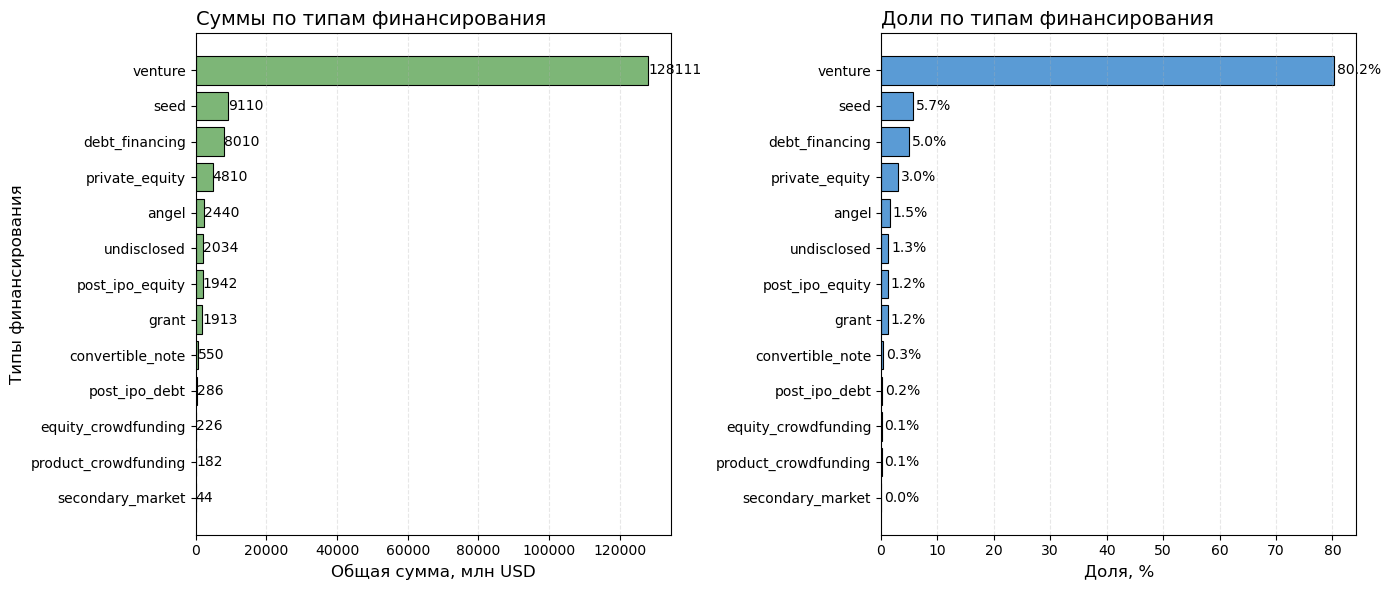

In [55]:
# Построим горизонтальную стобчатую диаграмму 'Распределение по типам финансирования'
total_sum = sums_types['total'].sum()
sums_types = sums_types.assign(share=(sums_types['total'] / total_sum) * 100)
sums_types_sorted = sums_types.sort_values('total', ascending=True)

fig, axs = plt.subplots(1, 2, figsize=(14, 6))
ax1, ax2 = axs

# Суммы
barhs1 = ax1.barh(
    sums_types_sorted.index,
    sums_types_sorted['total'],
    color='#7DB677',
    edgecolor='black',
    linewidth=0.8
)

ax1.set_title('Суммы по типам финансирования', loc='left', fontsize=14)
ax1.set_xlabel('Общая сумма, млн USD', fontsize=12)
ax1.set_ylabel('Типы финансирования', fontsize=12)

for bar in barhs1:
    w = bar.get_width()
    y = bar.get_y() + bar.get_height() / 2
    label = f'{w:.1f}' if w < 10 else f'{int(w)}'
    ax1.text(
        w + 0.2,
        y,
        label,
        ha='left',
        va='center',
        fontsize=10
    )

ax1.grid(axis='x', linestyle='--', alpha=0.3)


# Доли (%)
barhs2 = ax2.barh(
    sums_types_sorted.index,
    sums_types_sorted['share'],
    color='#5A9BD5',
    edgecolor='black',
    linewidth=0.8
)

ax2.set_title('Доли по типам финансирования', loc='left', fontsize=14)
ax2.set_xlabel('Доля, %', fontsize=12)

for bar in barhs2:
    w = bar.get_width()
    y = bar.get_y() + bar.get_height() / 2
    label = f'{w:.1f}%'
    ax2.text(
        w + 0.5,
        y,
        label,
        ha='left',
        va='center',
        fontsize=10
    )

ax2.grid(axis='x', linestyle='--', alpha=0.3)

plt.tight_layout()

fname_base = "types_finance_sum_and_share"
fname_png = f"{fname_base}.png"
fname_pdf = f"{fname_base}.pdf"

fig.savefig(png_dir / fname_png, dpi=150, bbox_inches="tight", pad_inches=0.1)
fig.savefig(pdf_dir / fname_pdf, bbox_inches="tight", pad_inches=0.1)

plt.show()

In [56]:
# Посчитаем популярность типов финансирования через превращение столбцов в булеву маску
types_popul = (
    types
    .gt(0)
    .sum()
    .sort_values(ascending=False)
)

types_popul = types_popul.to_frame(name='count')

path_file = interim_dir / 'types_popul.csv'
types_popul.to_csv(path_file)

types_popul

,count
venture,18139
seed,12349
debt_financing,3097
angel,2863
grant,918
undisclosed,741
private_equity,618
convertible_note,501
equity_crowdfunding,471
product_crowdfunding,195


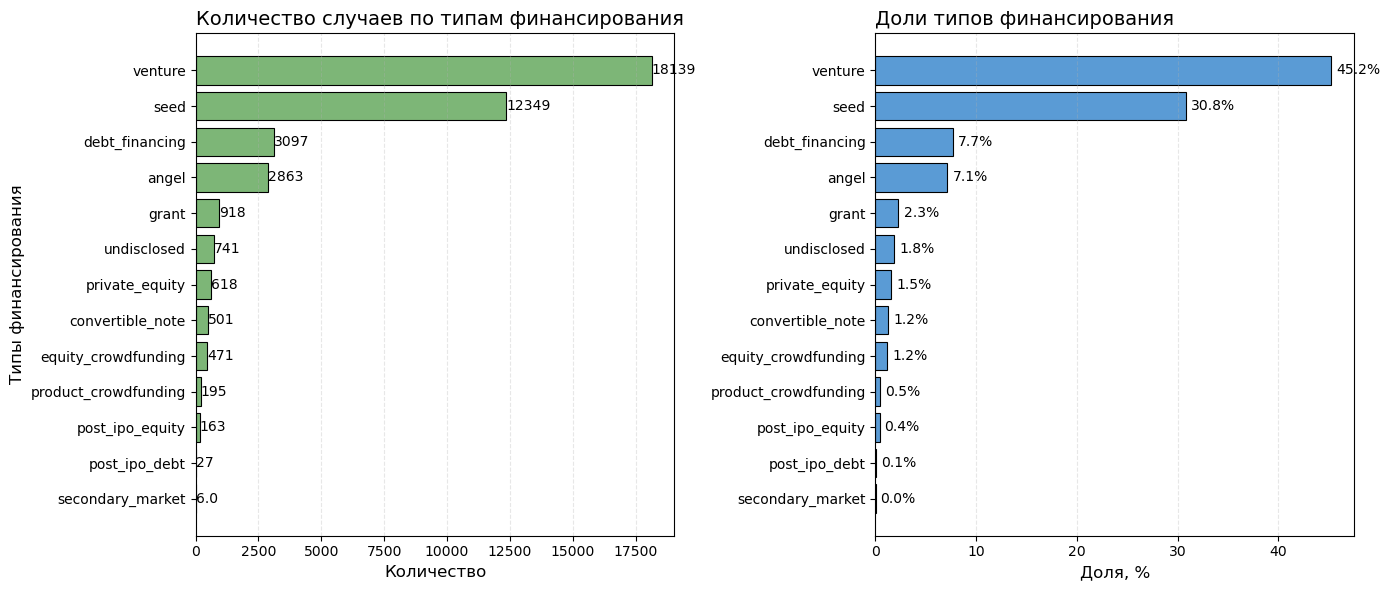

In [57]:
# Построим горизонтальную стобчатую диаграмму 'Распределение популярности типам финансирования'
total_count = types_popul['count'].sum()
types_popul = types_popul.assign(share=(types_popul['count'] / total_count) * 100)
types_sorted = types_popul.sort_values('count', ascending=True)

fig, axs = plt.subplots(1, 2, figsize=(14, 6))
ax1, ax2 = axs

# Количество (count)
bars1 = ax1.barh(
    types_sorted.index,
    types_sorted['count'],
    color='#7DB677',
    edgecolor='black',
    linewidth=0.8
)
ax1.set_title('Количество случаев по типам финансирования', loc='left', fontsize=14)
ax1.set_xlabel('Количество', fontsize=12)
ax1.set_ylabel('Типы финансирования', fontsize=12)
ax1.grid(axis='x', linestyle='--', alpha=0.3)

for bar in bars1:
    w = bar.get_width()
    y = bar.get_y() + bar.get_height() / 2
    label = f'{w:.1f}' if w < 10 else f'{int(w)}'
    ax1.text(w + 0.2, y, label, ha='left', va='center', fontsize=10)

# Доли
bars2 = ax2.barh(
    types_sorted.index,
    types_sorted['share'],
    color='#5A9BD5',
    edgecolor='black',
    linewidth=0.8
)
ax2.set_title('Доли типов финансирования', loc='left', fontsize=14)
ax2.set_xlabel('Доля, %', fontsize=12)
ax2.grid(axis='x', linestyle='--', alpha=0.3)

for bar in bars2:
    w = bar.get_width()
    y = bar.get_y() + bar.get_height() / 2
    ax2.text(w + 0.5, y, f'{w:.1f}%', ha='left', va='center', fontsize=10)

plt.tight_layout()

fname_base = "types_finance_cnt_and_share"
fig.savefig(png_dir / f"{fname_base}.png", dpi=150, bbox_inches="tight", pad_inches=0.1)
fig.savefig(pdf_dir / f"{fname_base}.pdf", bbox_inches="tight", pad_inches=0.1)

plt.show()

Построим график суммарных объёмов возвратов от разных типов финансирования за весь период на основе df_returns


In [58]:
# Выведим первые 5 строк датафрейма df_returns
df_returns.head()

,seed,venture,equity_crowdfunding,undisclosed,convertible_note,debt_financing,angel,grant,private_equity,post_ipo_equity,post_ipo_debt,secondary_market,product_crowdfunding
year,,,,,,,,,,,,,
2000,16.70,55.40,0.0,78.21,0.00,8.66,6.43,0.0,0.00,0.94,0.0,0.20,0.0
2001,2.88,23.49,0.0,21.50,0.01,4.49,1.18,0.0,0.00,0.46,0.0,0.46,0.0
2002,6.59,209.42,0.0,25.77,0.02,3.42,3.41,0.0,1.51,0.34,0.0,0.06,0.0
2003,7.74,233.86,0.0,9.40,0.01,1.09,3.41,0.0,1.62,2.11,0.0,0.08,0.0
2004,9.93,555.90,0.0,33.19,0.01,13.55,9.18,0.0,2.19,3.38,0.0,0.55,0.0


In [59]:
# Посчитаем общие суммы возвратов по типам финансирования
sums_ret_types = df_returns.sum().to_frame(name='total')
sums_ret_types = sums_ret_types.sort_values('total', ascending=False)

path_file = interim_dir / 'sums_ret_types.csv'
sums_ret_types.to_csv(path_file)

sums_ret_types

,total
venture,40578.62
debt_financing,4734.85
private_equity,3587.33
seed,2382.24
angel,1509.23
post_ipo_equity,1104.96
undisclosed,730.88
post_ipo_debt,91.03
convertible_note,34.79
secondary_market,5.20


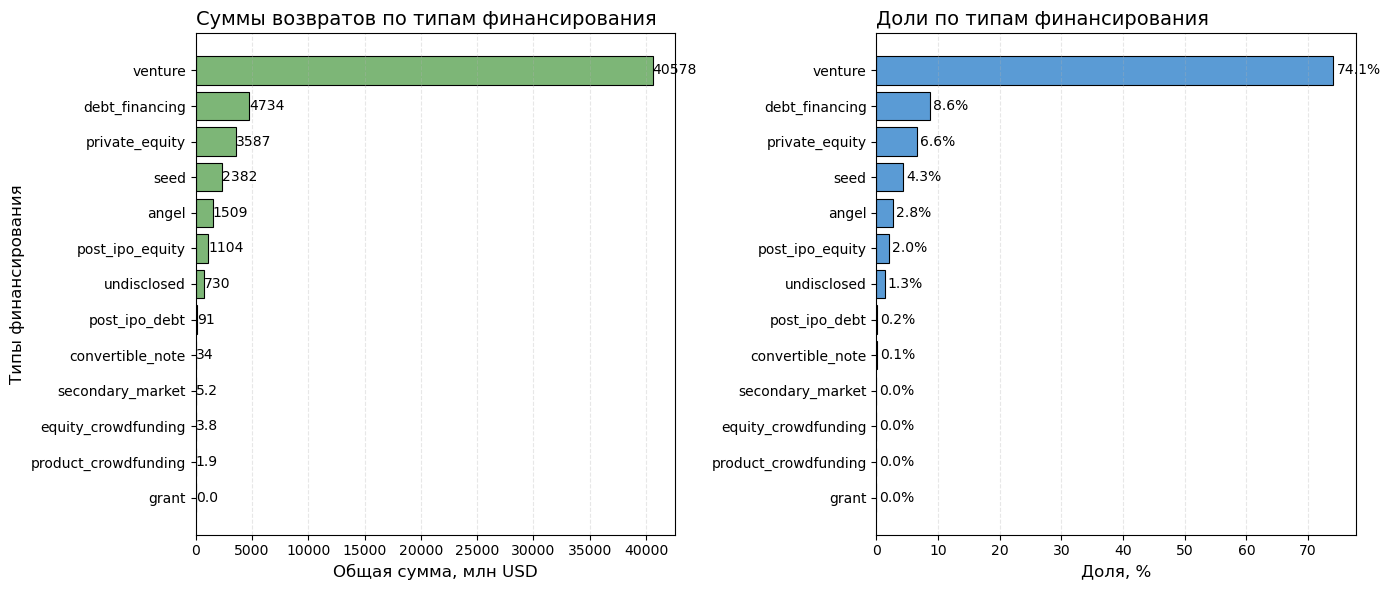

In [60]:
# Построим горизонтальную стобчатую диаграмму 'Распределение по суммам возвратов'
total_sum = sums_ret_types['total'].sum()
sums_ret_types = sums_ret_types.assign(share=(sums_ret_types['total'] / total_sum) * 100)
sums_ret_types_sorted = sums_ret_types.sort_values('total', ascending=True)

fig, axs = plt.subplots(1, 2, figsize=(14, 6))
ax1, ax2 = axs

# Суммы
barhs1 = ax1.barh(
    sums_ret_types_sorted.index,
    sums_ret_types_sorted['total'],
    color='#7DB677',
    edgecolor='black',
    linewidth=0.8
)

ax1.set_title('Суммы возвратов по типам финансирования', loc='left', fontsize=14)
ax1.set_xlabel('Общая сумма, млн USD', fontsize=12)
ax1.set_ylabel('Типы финансирования', fontsize=12)

for bar in barhs1:
    w = bar.get_width()
    y = bar.get_y() + bar.get_height() / 2
    label = f'{w:.1f}' if w < 10 else f'{int(w)}'
    ax1.text(
        w + 0.2,
        y,
        label,
        ha='left',
        va='center',
        fontsize=10
    )

ax1.grid(axis='x', linestyle='--', alpha=0.3)


# Доли (%)
barhs2 = ax2.barh(
    sums_ret_types_sorted.index,
    sums_ret_types_sorted['share'],
    color='#5A9BD5',
    edgecolor='black',
    linewidth=0.8
)

ax2.set_title('Доли по типам финансирования', loc='left', fontsize=14)
ax2.set_xlabel('Доля, %', fontsize=12)

for bar in barhs2:
    w = bar.get_width()
    y = bar.get_y() + bar.get_height() / 2
    label = f'{w:.1f}%'
    ax2.text(
        w + 0.5,
        y,
        label,
        ha='left',
        va='center',
        fontsize=10
    )

ax2.grid(axis='x', linestyle='--', alpha=0.3)

plt.tight_layout()

fname_base = "types_finance_sum_and_share_returns"
fname_png = f"{fname_base}.png"
fname_pdf = f"{fname_base}.pdf"

fig.savefig(png_dir / fname_png, dpi=150, bbox_inches="tight", pad_inches=0.1)
fig.savefig(pdf_dir / fname_pdf, bbox_inches="tight", pad_inches=0.1)

plt.show()

<a id='conc_analys_types_finance_total'></a>

#### Промежуточные выводы по разделу «Анализ типов финансирования по объёму и популярности»

Анализ проводился по очищенной выборке за период 2000–2014 гг. после исключения компаний с аномальным для своего сегмента объёмом финансирования. При интерпретации важно учитывать, что популярность типа финансирования — это количество случаев, когда тип встречается у компаний, а не число уникальных компаний: одна компания может учитываться в нескольких типах одновременно.

По объёму привлечённых средств. Суммарно по всем типам финансирования приходится около 161,4 млрд USD. Абсолютным лидером является `venture`: 129 092 млн USD, или 80,0 % всего объёма. Далее следуют `seed` — 9 431 млн USD (5,8 %), `debt_financing` — 8 178 млн USD (5,1 %), `private_equity` — 4 843 млн USD (3,0 %) и `angel` — 2 481 млн USD (1,5 %). На эти пять типов приходится около 95,4 % суммарного объёма, причём почти весь объём концентрируется в `venture`.

По популярности. Самыми часто используемыми типами являются `venture` — 18 820 случаев (44,5 %), `seed` — 13 375 (31,6 %), `debt_financing` — 3 265 (7,7 %), `angel` — 2 937 (7,0 %) и `grant` — 1 003 (2,4 %). На два самых популярных типа, `venture` и `seed`, приходится около 76,1 % всех случаев использования. Редкими остаются `post_ipo_equity` — 164 случая (0,39 %), `post_ipo_debt` — 27 (0,06 %) и `secondary_market` — 7 (0,02 %).


Сравнение объёма и популярности.

- Часто используются, но дают относительно небольшой объём:
  - `seed` - 31,6 % случаев и 5,8 % объема;
  - `angel` — 7,0 % случаев и 1,5 % объёма;
  - `grant` — 2,4 % случаев и 1,2 % объёма;

- Встречаются реже, но характеризуются крупными суммами:
  - `private_equity` — 1,5 % случаев, но 3,0 % объёма, в среднем около 7,6 млн USD;
  - `post_ipo_equity` — 0,39 % случаев и 1,21 % объёма, около 11,9 млн USD;
  - `post_ipo_debt` — 0,06 % случаев и 0,18 % объёма, около 10,6 млн USD;
  - `secondary_market` — всего 7 случаев, но средняя сумма около 6,5 млн USD, хотя общий вклад в объём минимален.

- Промежуточное положение занимает `debt_financing`: 7,7 % случаев и 5,1 % объёма, в среднем около 2,5 млн USD на случай.

- Встречаются реже и характеризуются малыми объемами:
  - краудфандинговые типы (`equity_crowdfunding`, `product_crowdfunding`) в сумме дают менее 0,3 % объёма.

- `venture` одновременно является и самым популярным, и самым объёмным типом: около 6,9 млн USD** в среднем на случай.

Возвраты по типам финансирования. По данным `df_returns` за весь период суммарные возвраты составили около 54,8 млрд USD. Здесь также лидирует `venture` — 40 578,62 млн USD (74,1 %). Далее идут `debt_financing` — 4 734,85 млн USD (8,6 %), `private_equity` — 3 587,33 млн USD (6,6 %), `seed` — 2 382,24 млн USD (4,3 %) и `angel` — 1 509,23 млн USD (2,8 %). На эти пять типов приходится около 96,4 % всех возвратов. При этом `grant` в датасете возвратов имеет нулевое значение (это ожидаемо, поскольку грантовое финансирование, как правило, не предполагает возврат инвестиций), а краудфандинговые типы и `secondary_market` дают минимальные суммы возвратов.

Таким образом, структура финансирования и возвратов сильно концентрирована вокруг `venture`. При этом `debt_financing` и `private_equity` при меньшей популярности дают заметную долю как привлечённых средств, так и возвратов, тогда как `seed`, `angel` и `grant` чаще используются, но характеризуются существенно меньшими средними объёмами.

[Вернуться к разделу «Работа с выбросами и анализ»](#data_analys)

[Вернуться в начало](#beginning)

<a id='dynamic_analysis'></a>

## Анализ динамики

1. [Динамика предоставления финансирования по годам](#dynamics_financing_provision)
    - [Промежуточные выводы по разделу](#conc_dynamics_financing_provision)
2. [Динамика размера общего финансирования по массовым сегментам рынка для растущих в 2014 году сегментов](#dynamics_total_finan_mass)
    - [Промежуточные выводы по разделу](#conc_dynamics_total_finan_mass)
3. [Годовая динамика доли возвращённых средств по типам финансирования](#dynamics_share_funds_returned)
    - [Промежуточные выводы по разделу](#conc_dynamics_share_funds_returned)

[Вернуться в начало](#beginning)

<a id='dynamics_financing_provision'></a>

### Динамика предоставления финансирования по годам

Используя столбцы `funding_total_usd` и `funding_rounds`, для каждой компании рассчитайте средний объём одного раунда финансирования.

На основе получившейся таблицы постройте графики, которые отразят:

- динамику типичного размера средств, которые стартапы получали в рамках одного раунда финансирования;
- динамику общего количества раундов за каждый год, то есть насколько активно происходили инвестиции на рынке (чем больше раундов, тем выше активность).

Когда будете строить графики в этом задании и следующих, используйте данные только по тем компаниям, которые остались в датасете после предыдущих фильтраций.

На основе полученных данных ответьте на вопросы:

- В каком году типичный размер средств, собранных в рамках одного раунда, был максимальным?
- Какая тенденция наблюдалась в 2014 году по количеству раундов и средств, выделяемых в рамках каждого раунда?

In [61]:
# Выведим первые 5 строк датафрейма df
df.head()

,name,homepage_url,category_list,market,funding_total_usd,status,country_code,state_code,region,city,...,round_e,round_f,round_g,round_h,category_finance,category,upper_bord,is_excess,funding_year,funding_year_cnt
0,DuPont,http://www.dupont.com,|Business Services|Agriculture|Automotive|Inve...,mid,9.00,operating,USA,DE,"Wilmington, Delaware",Wilmington,...,0.0,0.0,0.0,0.0,Единичное финансирование,средний,19.250000,False,2009.0,4472.0
1,University of Michigan,http://www.umich.edu/,|Education|,Education,7.70,operating,USA,MI,Detroit,Ann Arbor,...,0.0,0.0,0.0,0.0,Срок финансирования до года,массовый,11.821079,False,2013.0,12320.0
2,Case Western Reserve University,http://www.case.edu,|Education|,Education,0.54,operating,USA,OH,Cleveland,Cleveland,...,0.0,0.0,0.0,0.0,Единичное финансирование,массовый,11.821079,False,2014.0,6343.0
3,Duke University,http://www.duke.edu,|Education|,Education,8.70,operating,USA,NC,Raleigh,Durham,...,0.0,0.0,0.0,0.0,Единичное финансирование,массовый,11.821079,False,2014.0,6343.0
4,WeGame,http://www.WeGame.com,|Social Media|,Social Media,3.50,acquired,USA,CA,SF Bay Area,San Francisco,...,0.0,0.0,0.0,0.0,Срок финансирования до года,массовый,7.312500,False,2007.0,2820.0


In [62]:
# Добавим столбец со средней суммой на раунд
df['avg_round_sum'] = df['funding_total_usd'] / df['funding_rounds']


In [63]:
# Группируем среднюю сумму на раунд по годам и берем медиану
avg_sum_by_round = df.groupby('funding_year')['avg_round_sum'].median()
avg_sum_by_round

funding_year
2000.0    2.460000
2001.0    2.368582
2002.0    3.616667
2003.0    1.521966
2004.0    3.375000
2005.0    4.628875
2006.0    3.960000
2007.0    2.900000
2008.0    2.250000
2009.0    1.583333
2010.0    1.300000
2011.0    0.900000
2012.0    0.750000
2013.0    0.625000
2014.0    0.662634
Name: avg_round_sum, dtype: float64

In [64]:
# Выведим среднюю сумму на раунд за весь исследованный период
display(avg_sum_by_round.mean())

# Выведим медиану суммы на раунд за весь исследованный период
display(avg_sum_by_round.median())

2.193470473333333

2.25

In [65]:
summary = pd.DataFrame({
    'Показатель': [
        'Медиана размера раунда (по всем компаниям)',
        'Среднее размера раунда (по всем компаниям)',
        'Медиана годовых медиан',
        'Среднее годовых медиан'
    ],
    'Значение': [
        df['avg_round_sum'].median(),
        df['avg_round_sum'].mean(),
        avg_sum_by_round.median(),
        avg_sum_by_round.mean()
    ]
})

display(summary.assign(Значение=lambda x: x['Значение'].map('{:,.2f}'.format)))


,Показатель,Значение
0,Медиана размера раунда (по всем компаниям),1.00
1,Среднее размера раунда (по всем компаниям),2.92
2,Медиана годовых медиан,2.25
3,Среднее годовых медиан,2.19


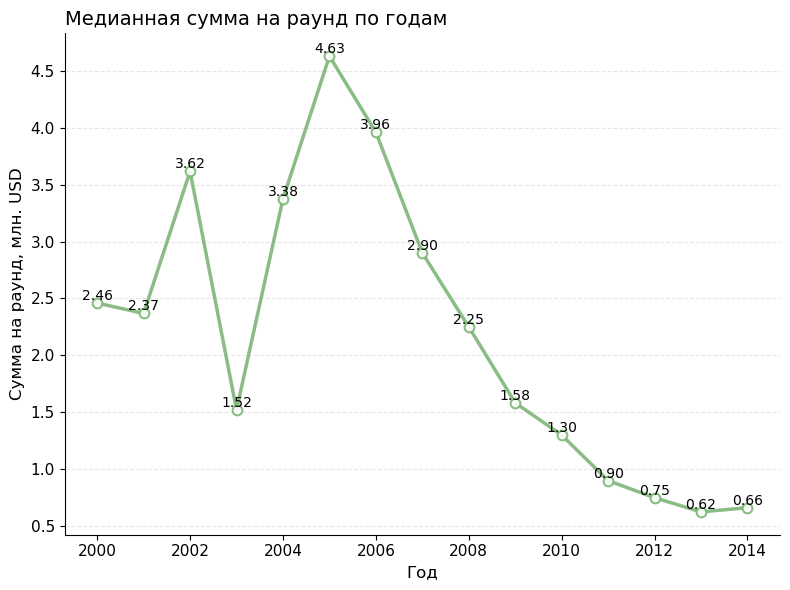

In [66]:
# Строим линейный график по сгруппированным данным
fig, ax = plt.subplots(figsize=(8, 6))

ax.plot(
    avg_sum_by_round.index,
    avg_sum_by_round.values,
    color='#7DB677',
    linewidth=2.5,
    marker='o',
    markersize=7,
    markerfacecolor='white',
    markeredgecolor='#7DB677',
    markeredgewidth=1.5,
    alpha=0.9
)

ax.set_title(
    'Медианная сумма на раунд по годам',
    fontsize=14,
    loc='left' 
)
ax.set_xlabel('Год', fontsize=12)
ax.set_ylabel('Сумма на раунд, млн. USD', fontsize=12)
ax.grid(True, axis='y', linestyle='--', alpha=0.3)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

for i, val in enumerate(avg_sum_by_round.values):
    formatted_val = f'{val:,.2f}'
    ax.text(
        avg_sum_by_round.index[i],
        val,
        formatted_val,
        ha='center',
        va='bottom',
        fontsize=10,
        color='black',
        zorder=3
    )

ax.tick_params(axis='both', which='major', labelsize=11)

plt.tight_layout()

fname_base = "avg_sum_by_round"
fname_png = f"{fname_base}.png"
fname_pdf = f"{fname_base}.pdf"

fig.savefig(png_dir / fname_png, dpi=150, bbox_inches="tight", pad_inches=0.1)
fig.savefig(pdf_dir / fname_pdf, bbox_inches="tight", pad_inches=0.1)

plt.show()


In [67]:
# Посчитаем общее количество раундов по годам
rounds_by_year = df.groupby('funding_year')['funding_rounds'].sum()
rounds_by_year

funding_year
2000.0      109.0
2001.0       58.0
2002.0       97.0
2003.0      120.0
2004.0      169.0
2005.0      931.0
2006.0     1825.0
2007.0     2820.0
2008.0     3624.0
2009.0     4472.0
2010.0     5975.0
2011.0     7368.0
2012.0     9312.0
2013.0    12320.0
2014.0     6343.0
Name: funding_rounds, dtype: float64

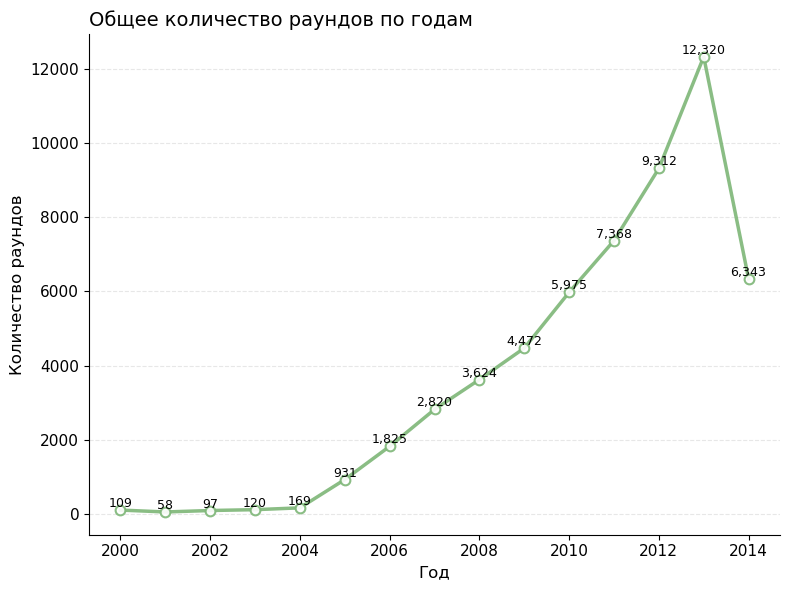

In [68]:
# Строим линейный график по сгруппированным данным
fig, ax = plt.subplots(figsize=(8, 6))

ax.plot(
    rounds_by_year.index,
    rounds_by_year.values,
    color='#7DB677',
    linewidth=2.5,
    marker='o',
    markersize=7,
    markerfacecolor='white',
    markeredgecolor='#7DB677',
    markeredgewidth=1.5,
    alpha=0.9
)

ax.set_title(
    'Общее количество раундов по годам',
    fontsize=14,
    loc='left' 
)
ax.set_xlabel('Год', fontsize=12)
ax.set_ylabel('Количество раундов', fontsize=12)
ax.grid(True, axis='y', linestyle='--', alpha=0.3)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

for i, val in enumerate(rounds_by_year.values):
    formatted_val = f'{val:,.0f}'
    ax.text(
        rounds_by_year.index[i],
        val,
        formatted_val,
        ha='center',
        va='bottom',
        fontsize=9,
        color='black',
        zorder=3
    )

ax.tick_params(axis='both', which='major', labelsize=11)

plt.tight_layout()

fname_base = "rounds_by_year"
fname_png = f"{fname_base}.png"
fname_pdf = f"{fname_base}.pdf"

fig.savefig(png_dir / fname_png, dpi=150, bbox_inches="tight", pad_inches=0.1)
fig.savefig(pdf_dir / fname_pdf, bbox_inches="tight", pad_inches=0.1)

plt.show()


In [69]:
# Выведим таблицу с количеством компаний по годам финансирования
yearly_counts = (
    df.groupby('funding_year')['name']
      .count()
      .reset_index()
      .rename(columns={'name': 'Количество компаний', 'funding_year': 'Год финансирования'})
      .sort_values('Год финансирования')
)

display(yearly_counts)

,Год финансирования,Количество компаний
0,2000.0,61
1,2001.0,29
2,2002.0,47
3,2003.0,60
4,2004.0,89
5,2005.0,682
6,2006.0,1145
7,2007.0,1581
8,2008.0,1952
9,2009.0,2487


<a id='conc_dynamics_financing_provision'></a>

#### Промежуточные выводы по разделу «Динамика предоставления финансирования по годам»

Для каждой компании рассчитан средний объём одного раунда как `funding_total_usd / funding_rounds`. Затем по каждому году (на основе `mid_funding_at`) взята медиана этого показателя (устойчива к выбросам), а также суммарное количество раундов (`funding_rounds`).

Типичный размер раунда (медиана). Максимум наблюдается в 2005 году — около 4,50 млн USD на раунд. Далее показатель устойчиво снижается: с ~3,90 млн в 2006 году до ~0,56 млн в 2013–2014 годах. Таким образом, типичный чек за раунд за десятилетие сократился почти в 8 раз: рынок стал более «массовым», но отдельные раунды — заметно мельче.

Количество раундов. Суммарное число раундов росло практически монотонно: со 109 в 2000 году до 12 320 в 2013 году — пик активности инвесторов. В 2014 году показатель снизился до 6 343 раундов, однако, как было установлено ранее, данные за 2014 год неполные (особенно за ноябрь–декабрь), поэтому это снижение нельзя интерпретировать как реальное сокращение рынка.

Ответы на вопросы:
- Максимальный типичный размер средств в рамках одного раунда — в 2005 году (~4,5 млн USD).
- Тенденция 2014 года: количество раундов снизилось относительно 2013 года (6 343 против 12 320), но это, вероятнее всего, следствие неполноты данных; средний размер раунда остался на минимальном уровне (~0,56 млн USD), продолжая понижательную тенденцию предыдущих лет.

| Год | Количество компаний |
|-----|----------|
| 2000 | 61 |
| 2001 | 29 |
| 2002 | 47 |
| 2003 | 60 |
| 2004 | 89 |
| 2005 | 682 |
| 2006 | 1145 |
| 2007 | 1581 |
| 2008 | 1952 |
| 2009 | 2487 |
| 2010 | 3326 |
| 2011 | 4137 |
| 2012 | 5189 |
| 2013 | 7339 |
| 2014 | 5348 |

Расхождение трендов — рост числа раундов на фоне падения среднего чека — указывает на то, что со временем всё больше компаний (в 2014 имеется провал из-за неполных данных) стали привлекать финансирование. При этом снижение размера одного раунда остановилось с учетом неполноты данных за 2014 год. Рынок становился более массовым: множество небольших и средних раундов вместо небольшого числа крупных. Средний размер раунда финансирования компании составляет 2,92 млн USD, медианный - 1,00 млн USD.


Это согласуется с ранее сделанным выводом о доминировании `seed` и `venture` по популярности.

[Вернуться к разделу «Анализ динамики»](#dynamic_analysis)

[Вернуться в начало](#beginning)

<a id='dynamics_total_finan_mass'></a>

### Динамика размера общего финансирования по массовым сегментам рынка для растущих в 2014 году сегментов

Составьте сводную таблицу, в которой указывается суммарный размер общего финансирования `funding_total_usd` по годам и сегментам рынка. Отберите из неё только те сегменты, которые показывали рост размера суммарного финансирования в 2014 году по сравнению с 2013.

На графике отразите, как менялся суммарный размер общего финансирования в каждом из отобранных сегментов по годам, за которые у вас достаточно данных. Рассматривайте только массовые сегменты, а средние и нишевые исключите.

На основе графика сделайте вывод о том, какие сегменты показывают наиболее быстрый и уверенный рост.

In [70]:
# Построим сводную таблицу с данными о суммарном размере общего финансирования по годам и сегментам рынка
segments_total_sum = df.pivot_table(
    index='market',
    columns='funding_year', 
    values='funding_total_usd', 
    aggfunc='sum',
    fill_value=0
)
segments_total_sum

funding_year,2000.0,2001.0,2002.0,2003.0,2004.0,2005.0,2006.0,2007.0,2008.0,2009.0,2010.0,2011.0,2012.0,2013.0,2014.0
market,,,,,,,,,,,,,,,
Advertising,14.470000,8.778321,24.500000,10.500000,6.000000,127.196022,299.299458,556.704331,622.673464,563.446005,631.617869,410.730737,521.137032,524.915135,207.792333
Analytics,14.822803,0.000000,7.500000,3.840000,3.000000,79.014044,139.701311,98.829000,208.077840,140.949327,253.739903,443.333373,539.214309,622.821367,151.461613
Apps,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.310600,0.000000,4.300000,7.219000,6.123779,18.374071,32.601125,28.868621,66.237730
Automotive,0.000000,0.000000,0.000000,4.530000,0.000000,22.500000,12.660000,37.712601,59.478635,20.800311,17.696916,76.452163,35.557677,117.572526,69.034162
Big Data,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,7.780000,2.452515,0.597375,39.233297,60.369158,86.413341,78.698922,79.232600
Biotechnology,0.000000,0.000000,0.000000,85.531178,97.184859,480.063583,903.500543,1704.078338,1716.033000,3915.900521,4894.500078,4967.551850,4931.138800,5694.269809,2509.638562
Clean Technology,0.000000,0.000000,34.390435,50.352939,50.427954,19.420000,131.473889,749.711239,3165.808492,1963.502838,1604.429454,1545.603337,958.011189,1203.060535,688.686785
Cloud Computing,11.500000,0.000000,0.000000,0.000000,0.000000,0.000000,9.951809,20.354343,44.375000,52.223719,8.525538,73.151398,74.421582,84.846778,73.440856
Consulting,4.500000,0.000000,0.000000,0.000000,0.000000,44.862000,23.965548,70.346345,19.061080,62.715165,81.264877,43.413397,65.922756,93.321324,54.298022


In [71]:
# Выводим отфильтрованную таблицу с данными где сумма финансирования по годам 2014 больше 2013
segments_total_sum_filtr = segments_total_sum[
    (segments_total_sum[2014] > segments_total_sum[2013])
]
segments_total_sum_filtr

funding_year,2000.0,2001.0,2002.0,2003.0,2004.0,2005.0,2006.0,2007.0,2008.0,2009.0,2010.0,2011.0,2012.0,2013.0,2014.0
market,,,,,,,,,,,,,,,
Apps,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,1.310600,0.000000,4.300000,7.219000,6.123779,18.374071,32.601125,28.868621,66.237730
Big Data,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,7.780000,2.452515,0.597375,39.233297,60.369158,86.413341,78.698922,79.232600
Design,0.000000,0.000000,0.000000,0.000000,0.00000,9.300000,0.707000,10.800000,5.944302,2.150144,17.239975,8.899967,39.630692,60.958835,68.988516
Internet,10.000000,0.000000,1.100000,0.000000,10.50000,1.775000,0.005000,4.495379,23.412964,38.195773,36.657500,36.859032,28.288685,69.732096,117.830756
Manufacturing,56.659310,2.368582,0.000000,4.269608,3.00000,61.770000,163.957751,147.726051,173.054260,422.862531,244.329661,561.639285,522.205168,393.936634,416.332314
Medical,24.000000,0.000000,0.000000,0.000000,0.00000,11.090000,20.250000,2.100000,28.812744,11.566200,25.590338,28.540962,44.039600,64.469424,175.236064
Real Estate,2.500000,0.000000,5.275000,6.292200,0.00000,0.250000,2.080000,33.220000,46.613100,38.840213,37.344608,20.015128,77.320857,92.207655,115.567364
SaaS,0.000000,0.000000,2.000000,0.000000,0.00000,5.240000,4.791121,14.652595,27.226900,13.536585,32.609390,32.223749,49.699912,79.576613,92.807752
Startups,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,5.010387,0.460700,2.111966,19.654403,12.358782,18.080552,41.501837


In [72]:
# Убираем из таблицы строки с mid и niche
segments_total_sum_filtr = segments_total_sum_filtr.query("market not in ['mid', 'niche']")
segments_by_year = segments_total_sum_filtr.T
segments_by_year

market,Apps,Big Data,Design,Internet,Manufacturing,Medical,Real Estate,SaaS,Startups,Technology
funding_year,,,,,,,,,,
2000.0,0.000000,0.000000,0.000000,10.000000,56.659310,24.000000,2.500000,0.000000,0.000000,0.000000
2001.0,0.000000,0.000000,0.000000,0.000000,2.368582,0.000000,0.000000,0.000000,0.000000,22.160000
2002.0,0.000000,0.000000,0.000000,1.100000,0.000000,0.000000,5.275000,2.000000,0.000000,11.000000
2003.0,0.000000,0.000000,0.000000,0.000000,4.269608,0.000000,6.292200,0.000000,0.000000,0.000000
2004.0,0.000000,0.000000,0.000000,10.500000,3.000000,0.000000,0.000000,0.000000,0.000000,1.750000
2005.0,0.000000,0.000000,9.300000,1.775000,61.770000,11.090000,0.250000,5.240000,0.000000,50.728425
2006.0,1.310600,0.000000,0.707000,0.005000,163.957751,20.250000,2.080000,4.791121,0.000000,22.791000
2007.0,0.000000,7.780000,10.800000,4.495379,147.726051,2.100000,33.220000,14.652595,0.000000,180.190209
2008.0,4.300000,2.452515,5.944302,23.412964,173.054260,28.812744,46.613100,27.226900,5.010387,277.726238


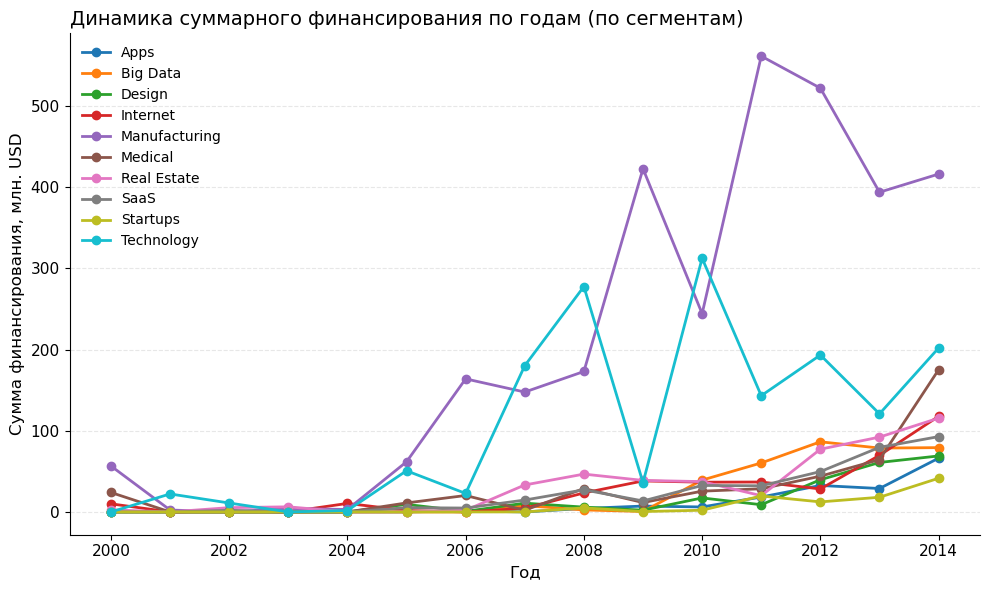

In [73]:
# Строим линейный график по сегментам по годам
fig, ax = plt.subplots(figsize=(10, 6))

for i, col in enumerate(segments_by_year.columns):
    ax.plot(
        segments_by_year.index,
        segments_by_year[col],
        linewidth=2,
        marker='o',
        markersize=6,
        label=col
    )

ax.set_title('Динамика суммарного финансирования по годам (по сегментам)', fontsize=14, loc='left')
ax.set_xlabel('Год', fontsize=12)
ax.set_ylabel('Сумма финансирования, млн. USD', fontsize=12)
ax.legend(loc='best', frameon=False)
ax.grid(True, axis='y', linestyle='--', alpha=0.3)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.tick_params(axis='both', which='major', labelsize=11)
plt.tight_layout()

fname_base = "segments_by_year"
fname_png = f"{fname_base}.png"
fname_pdf = f"{fname_base}.pdf"

fig.savefig(png_dir / fname_png, dpi=150, bbox_inches="tight", pad_inches=0.1)
fig.savefig(pdf_dir / fname_pdf, bbox_inches="tight", pad_inches=0.1)

plt.show()

<a id='conc_dynamics_total_finan_mass'></a>

#### Промежуточные выводы по разделу «Динамика размера общего финансирования по массовым сегментам рынка для растущих в 2014 году сегментов»

Для анализа была построена сводная таблица суммарного объёма финансирования `funding_total_usd` по годам (`funding_year`) и сегментам рынка (`market`). Из неё были отобраны только те сегменты, у которых суммарное финансирование в 2014 году превысило показатель 2013 года. Дополнительно из рассмотрения исключены агрегированные группы `mid` и `niche`. 

В итоге в анализ вошли 10 массовых сегментов

- Medical — один из лидеров по относительному приросту. Сегмент демонстрирует устойчивый восходящий тренд на протяжении последних пяти лет: 25,6 млн (2010) → 28,5 млн (2011) → 44,0 млн (2012) → 64,5 млн (2013) → 175,2 млн (2014), увеличившись в 2014 году почти в 2,7 раза к 2013 году. Именно этот сегмент можно считать наиболее перспективным для инвестиций: рост не единичный, а продолжается несколько лет подряд.

- Apps — второй по темпам роста сегмент: 6,1 млн (2010) → 18,4 млн (2011) → 32,6 млн (2012) → 28,9 млн (2013) → 66,2 млн (2014). Рост также носит устойчивый характер, за исключением небольшой просадки в 2013 году; в 2014 году — рост более чем в 2,3 раза.

- Startups — также как Madical один из лидеров по относительному приросту (~+130 %), однако база роста очень мала: 2,1 млн (2010) → 19,7 млн (2011) → 12,4 млн (2012) → 18,1 млн (2013) → 41,5 млн (2014). Тренд положительный, но объёмы финансирования пока невелики, а динамика неустойчива.

- Real Estate — уверенный и последовательный рост с 2011 года: 20,0 млн (2011) → 77,3 млн (2012) → 92,2 млн (2013) → 115,6 млн (2014). Сегмент медленно, но стабильно набирает обороты.

- Internet и Technology — также показывают рост в 2014 году (+69 % и +67 % соответственно), однако их траектория волатильна. Например, у Technology значения колебались: 312,5 млн (2010) → 143,2 млн (2011) → 193,3 млн (2012) → 120,9 млн (2013) → 202,0 млн (2014), и текущий уровень 2014 года ниже пика 2010 года. У Internet же рост в 2014 году опирается на сравнительно небольшой абсолютный объём.

- Manufacturing формально попал в список выросших, но прирост всего +6 %, при этом в 2011 году сегмент достигал пика 561,6 млн, после чего снижался до 393,9 млн (2013). Текущее «оживление» в 2014 году не компенсирует предшествующее падение, и говорить о быстром росте этого сегмента нет оснований.

- SaaS, Design и особенно Big Data показали меньший прирост (+17 %, +13 % и +1 % соответственно).

Итог. Наиболее быстрый и уверенный рост демонстрируют сегменты Medical, Apps и Real Estate — их суммарное финансирование увеличивается несколько лет подряд. Startups, Internet и Technology росли высокими темпами в 2014 году, но их динамика менее стабильна и/или опирается на сравнительно небольшую базу. Manufacturing, SaaS, Design и Big Data также вошли в список выросших, но прирост ниже чем у других сегментов. Тем не менее важно учитывать, что 2014 год из-за неполных данных занижает показатели всех сегментов.

[Вернуться к разделу «Анализ динамики»](#dynamic_analysis)

[Вернуться в начало](#beginning)

<a id='dynamics_share_funds_returned'></a>

### Годовая динамика доли возвращённых средств по типам финансирования

Заказчик хочет знать, какая часть вложенных или выданных денег со временем возвращается обратно инвесторам или финансистам. Ваша цель — для каждого года и каждого вида финансирования рассчитать нормированные значения возврата средств: то есть какую долю возвращённые средства составляют от предоставленных. При этом слишком большие аномальные значения, то есть неадекватные выбросы, нужно заменить на пропуски.

Совет: когда будете делить сумму возвращённых средств на суммарный объём привлечённого финансирования по конкретному году, добавьте к знаменателю небольшое число, например, `1e-60`. Это поможет избежать деления на ноль.

Постройте график, на котором отобразите нормированные значения возврата средств для типов финансирования `venture`, `debt_financing`, `private_equity`, `seed` и `angel`.

Сделайте вывод о том, в каких типах финансирования наблюдается наиболее устойчивый рост показателя.

In [74]:
# Функция для определения границ межквартильного размаха и обработки выбросов
def iqr_borders_clean(df, multiplier=1.5):
    """
    Возвращает новый DataFrame, где выбросы заменены на NaN.
    Не меняет исходный df.
    multiplier=1.5 — классическое правило IQR.
    """
    clean_df = df.copy()
    for col in clean_df.columns:
        q1 = clean_df[col].quantile(0.25)
        q3 = clean_df[col].quantile(0.75)
        iqr = q3 - q1
        lower = q1 - multiplier * iqr
        upper = q3 + multiplier * iqr
        clean_df.loc[(clean_df[col] < lower) | (clean_df[col] > upper), col] = np.nan
    return clean_df

In [75]:
# Создадим датафрейм с данными о финансировании компаний и возвратам по типу финансирования и году финансирования
finance = df[[
    'funding_year',
    'seed',
    'venture',
    'equity_crowdfunding',
    'undisclosed',
    'convertible_note',
    'debt_financing',
    'angel',
    'grant',
    'private_equity',
    'post_ipo_equity',
    'post_ipo_debt',
    'secondary_market',
    'product_crowdfunding'
]].copy()
finance = finance.rename(columns={'funding_year': 'year'})
# Столбец 'year' -> int
finance['year'] = finance['year'].astype(int)
#finance = finance.set_index('year')

finance_by_year = finance.groupby('year').sum()
finance_by_year = finance_by_year + 1e-60

returns = df_returns.copy()

In [76]:
# Получим доли возвратов по типу финансирования и году финансирования
frac_finance_by_year_types = returns / finance_by_year
frac_finance_by_year_types = frac_finance_by_year_types * 1000000
frac_finance_by_year_types = iqr_borders_clean(frac_finance_by_year_types)
frac_finance_by_year_types

,seed,venture,equity_crowdfunding,undisclosed,convertible_note,debt_financing,angel,grant,private_equity,post_ipo_equity,post_ipo_debt,secondary_market,product_crowdfunding
year,,,,,,,,,,,,,
2000,0.998557,0.169857,0.000000,0.697042,0.000000e+00,0.618571,0.266956,0.0,0.000000,2.710694e-01,0.000000,2.591054e-02,0.000000
2001,1.079592,0.111534,0.000000,0.587483,6.666667e-03,NaN,1.180000,0.0,0.000000,4.600000e+65,0.000000,4.600000e+65,0.000000
2002,0.629707,0.682820,0.000000,0.608878,NaN,0.223388,1.136667,0.0,0.201333,1.133333e+00,0.000000,6.000000e+64,0.000000
2003,0.537748,0.633760,0.000000,0.914397,1.000000e+64,1.038095,0.605720,0.0,NaN,NaN,0.000000,8.000000e+64,0.000000
2004,0.556155,0.842401,0.000000,0.566719,1.000000e+64,0.470215,0.833504,0.0,NaN,NaN,0.000000,5.500000e+65,0.000000
2005,0.777562,0.548927,0.000000,NaN,NaN,0.344964,0.509894,0.0,0.480000,7.318565e-01,0.000000,5.000000e+64,0.000000
2006,0.934111,0.345073,NaN,0.803434,1.663181e-01,0.829083,0.675999,0.0,0.947881,NaN,0.000000,1.200000e+65,0.000000
2007,0.368202,0.297975,NaN,0.504971,2.280972e-01,0.602488,0.825843,0.0,0.590113,2.030000e+00,0.000000,5.700000e+65,0.000000
2008,0.301587,0.191301,NaN,0.348874,6.984493e-02,0.930676,0.414156,0.0,0.679925,2.341111e+00,0.000000,4.700000e+65,0.000000


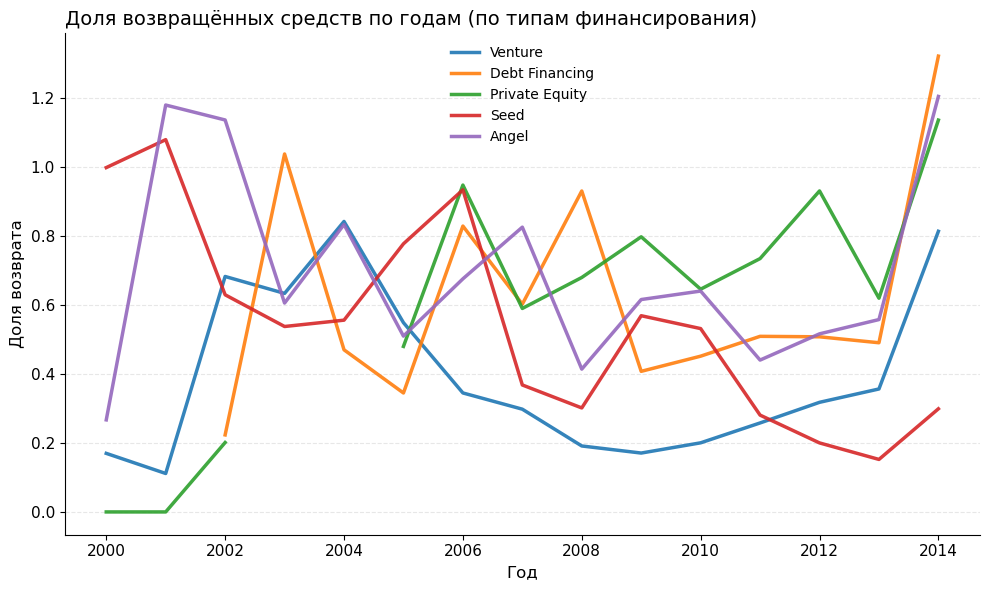

In [77]:
# Построим линейный график для каждого типа финансирования по долям возвратов
cols = [
    'venture', 
    'debt_financing', 
    'private_equity', 
    'seed', 
    'angel'
]

fig, ax = plt.subplots(figsize=(10, 6))

for i, col in enumerate(cols):
    # Берем серию для конкретного типа
    series = frac_finance_by_year_types[col]
    
    ax.plot(
        series.index,
        series.values,
        linewidth=2.5,
        alpha=0.9,
        label=col.replace('_', ' ').title()
    )

ax.set_title('Доля возвращённых средств по годам (по типам финансирования)', fontsize=14, loc='left')
ax.set_xlabel('Год', fontsize=12)
ax.set_ylabel('Доля возврата', fontsize=12)
ax.grid(True, axis='y', linestyle='--', alpha=0.3)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.legend(loc='best', frameon=False, fontsize=10)
ax.tick_params(axis='both', which='major', labelsize=11)
plt.tight_layout()

fname_base = "frac_finance_by_year_types"
fig.savefig(png_dir / f"{fname_base}.png", dpi=150, bbox_inches="tight", pad_inches=0.1)
fig.savefig(pdf_dir / f"{fname_base}.pdf", bbox_inches="tight", pad_inches=0.1)

plt.show()

<a id='conc_dynamics_share_funds_returned'></a>

#### Промежуточные выводы по разделу «Годовая динамика доли возвращённых средств по типам финансирования»

**Оценка устойчивости по годам с 2009 по 2014**

`venture`. 17,1 % (2009) → 20,0 % (2010) → 25,8 % (2011) → 31,8 % (2012) → 35,7 % (2013) → 81,4 % (2014). Пять лет подряд значения росли — это один из наиболее последовательных трендов среди всех типов. Провалы отсутствуют.

`debt_financing`. 40,8 % (2009) → 45,2 % (2010) → 50,9 % (2011) → 50,8 % (2012) → 49,1 % (2013) → 132,2 % (2014). Рост с 2009 по 2011 годы. Отсутствие роста с 2011 по 2013. Затем резкий рост в 2014 году.

`private_equity`. 79,8 % (2009) → 64,6 % (2010) → 73,5 % (2011) → 93,1 % (2012) → 62,0 % (2013) → 113,6 % (2014). Демонстрирует скачки.

`seed`. 56,9 % (2009) → 53,2 % (2010) → 28,1 % (2011) → 20,0 % (2012) → 15,2 % (2013) → 29,9 % (2014). Данный сегмент демонстирует заметное снижение.

`angel`. 62,6 % (2009) → 64,1 % (2010) → 44,0 % (2011) → 51,6 % (2012) → 55,8 % (2013) → 120,5 % (2014). Заметен рост, но лишь с 2011 года.

Наиболее устойчивым и последовательным оказался тренд по категории `venture`: доля стабильно росла пять лет подряд — с 17,1 % в 2009 году до 35,7 % в 2013 году провалов.

Категория `seed`, напротив, демонстрировала выраженный нисходящий тренд: доля снизилась с 56,9 % в 2009 году до 15,2 % в 2013 году.

Остальные типы (`debt_financing`, `private_equity`, `angel`) показывали динамику с колебаниями.

Значения 2014 г. для всех пяти типов резко выросли, что нетипично на фоне предыдущей динамики. Наиболее вероятное объяснение — неполнота данных о финансировании за 2014 год.

[Вернуться к разделу «Анализ динамики»](#dynamic_analysis)

[Вернуться в начало](#beginning)

<a id='conclusion'></a>

## Итоговый вывод

Проведённое исследование охватило период 2000–2014 гг. (годы с достаточным числом раундов — от 50 и выше) и очищенную выборку из 33 472 компаний после удаления дубликатов, записей без итоговой суммы финансирования и аномалий по IQR внутри сегментов.

Предобработка данных. 
   - Удалены лишние пробелы в названиях столбцов, приведены к `snake_case`.  
   - Столбец `funding_total_usd` очищен от разделителей разрядов и приведён к числовому типу.  
   - Столбцы с датами преобразованы в `datetime`.   
   - Частично восстановлен столбец `mid_funding_at` как середина интервала между первым и последним раундами.

Структура выборки и её ограничения.
- После удаления дубликатов и строк без общей суммы финансирования (`funding_total_usd`) число наблюдений сократилось с 54 294 до 40 907 (24,66 % записей). На этом этапе IQR-аномалии ещё не исключались: 40 907 — это `df_clean` до фильтрации аномалий. После исключения аномалий и ограничения периода 2000–2014 в итоговой выборке остаётся 33 472 компании.
- 2014 год неполный: в ноябре зафиксировано 306 компаний против 497–740 в январе–октябре, в декабре — всего 23. Провал числа раундов в 2014 году (6 343 против 12 320 в 2013) — следствие неполноты данных, а не спада рынка.

Группы по срокам финансирования.
- Единичное финансирование: ≈59 % компаний, но лишь ≈30,6 % объёма средств.
- Срок до года: ≈11 % компаний и ≈7,5 % объёма.
- Срок более года: ≈30 % компаний, но ≈61,9 % объёма инвестиций.

Сегментация рынка.
- 48 массовых сегментов (>120 компаний) охватывают ≈87,8 % компаний; средние (35–120) — ≈10,0 %; нишевые (<35) — ≈2,2 %.
- Крупнейшие массовые сегменты: `Software` (4 812 компаний), `Biotechnology` (3 590), `Mobile` (2 344), `E-Commerce` (1 866), `Curated Web` (1 693).
- Индивидуальные средние и нишевые сегменты объединены в `mid` и `niche`.

Типы финансирования: объём и популярность.
- По объёму: `venture` — 129 092 млн USD (80,0 %), `seed` — 5,8 %, `debt_financing` — 5,1 %, `private_equity` — 3,0 %, `angel` — 1,5 %. Пять типов дают ≈95,4 % всего объёма.
- По популярности: `venture` — 18 820 случаев (44,5 %), `seed` — 13 375 (31,6 %), `debt_financing` — 7,7 %, `angel` — 7,0 %, `grant` — 2,4 %.
- Часто, но небольшими суммами: `seed` (треть случаев при <6 % объёма), `angel`, `grant`.
- Редко, но крупными суммами: `private_equity` (1,5 % случаев при 3,0 % объёма), `post_ipo_equity` (0,39 % при 1,21 %), `post_ipo_debt` (0,06 % при 0,18 %).
- Возвраты. (`df_returns`): `venture` — 40 578,62 млн USD (74,1 %), `debt_financing` — 8,6 %, `private_equity` — 6,6 %, `seed` — 4,3 %, `angel` — 2,8 %. `grant` — 0, краудфандинг и `secondary_market` — минимальные суммы.

Показатели.
- Типичный (медианный) размер раунда достиг пика в 2005 году — ≈4,5 млн USD — и затем устойчиво снижался: к 2013–2014 гг. до ≈0,56 млн USD. Типичный чек за раунд сократился почти в 8 раз.
- Число компаний росло с 61 (2000) до 7 339 (2013); число раундов — с 109 до 12 320. В 2014 — 5 348 компаний и 6 343 раунда.
- Медиана размера раунда по всем компаниям — 1,00 млн USD, среднее — 2,92 млн USD. Медиана годовых медиан — 2,25 млн USD.

Работа с аномалиями.
- Признак `is_excess` (компании с объёмом выше верхней границы IQR своего сегмента) сохранён в данных. Топ сегментов по доле аномалий: `Real Estate` (17,2 %), `Entertainment` (16,7 %), `Consulting` (16,6 %), `Search` (16,5 %), `Cloud Computing` (16,4 %).


Ограничения исследования

- Неполнота 2014 года — главное ограничение: ноябрь–декабрь практически отсутствуют, поэтому итоговые годовые суммы и число раундов за 2014 занижены.
- Период 2000–2014 отсекает ранние годы с малым числом раундов (<50).
- Сегментация по IQR внутри `market` чувствительна к правой асимметрии: около 15 % наблюдений ожидаемо попадают в «выбросы» в каждом сегменте. Это статистический эффект, а не обязательно аномальная природа компаний.
- Популярность типа считается как число случаев с ненулевой суммой: одна компания может учитываться в нескольких типах одновременно.
- Данные о возвратах (`df_returns`) даны в агрегированном по годам виде без разбивки по компаниям и сегментам, поэтому их нельзя напрямую сопоставить с `funding_total_usd` по конкретным сделкам.



Динамика рынка (2000–2014). 

Суммарное число раундов росло почти монотонно:
с 109 в 2000 году до 12 320 в 2013 — пика активности инвесторов. В 2014 году
зафиксировано 6 343 раунда, однако данные за 2014 год неполные (особенно ноябрь–декабрь),
поэтому это снижение нельзя интерпретировать как реальное сокращение рынка.
На фоне роста числа раундов типичный чек за раунд (медиана по годам) устойчиво падал:
с ~4,50 млн USD в 2005 году до ~0,56 млн USD в 2013–2014 годах. Рынок становился
более массовым: много небольших и средних раундов вместо нескольких крупных.

Рост сегментов в 2014 году (относительно 2013). Среди массовых сегментов рост
суммарного финансирования в 2014 году показали:
- `Medical` — с 64,5 до 175,2 млн USD (+110,8 млн, +172 %);
- `Technology` — с 120,9 до 202,0 млн USD (+81,1 млн, +67 %);
- `Internet` — с 69,7 до 117,8 млн USD (+48,1 млн, +69 %);
- `Apps` — с 28,9 до 66,2 млн USD (+37,4 млн, +129 %);
- `Startups` — с 18,1 до 41,5 млн USD (+23,4 млн, +129 %);
- `Manufacturing` — с 393,9 до 416,3 млн USD (+22,4 млн, +6 %);
- `Real Estate` — с 92,2 до 115,6 млн USD (+23,4 млн, +25 %);
- `SaaS` — с 79,6 до 92,8 млн USD (+13,2 млн, +17 %).

Возвраты по типам финансирования. По данным `df_returns` за весь период суммарные
возвраты составили ~54,8 млрд USD, из них:
- `venture` — 40 578,6 млн USD (74,1 %);
- `debt_financing` — 4 734,9 млн USD (8,6 %);
- `private_equity` — 3 587,3 млн USD (6,6 %);
- `seed` — 2 382,2 млн USD (4,3 %);
- `angel` — 1 509,2 млн USD (2,8 %).

Крупнейшие по числу компаний сегменты — `Software` (4 812 компаний), `Biotechnology` (3 590) и `Mobile` (2 344) — по объёму финансирования в 2014 году сократились относительно 2013 (`Software`: 1 949 → 1 353 млн USD; `Biotechnology`: 5 694 → 2 510 млн USD; `Mobile`: 1 192 → 576 млн USD).
Наиболее быстрый и уверенный рост в 2014 году показал `Medical`: +110,8 млн USD (+172 %) к 2013 году.

**Рекомендации заказчику**

Крупнейшие по числу компаний сегменты — `Software`, `Biotechnology`и `Mobile` — по объёму финансирования в 2014 году сократились относительно 2013. Поэтому ориентироваться только на «крупнейший по числу компаний» сегмент было бы ошибкой. Наиболее быстрый и уверенный рост в 2014 году показал `Medical` к 2013 году. Именно его и стоит назвать основным направлением для инвестиций.

В качестве ключевого инструмента финансирования целесообразно рассматривать venture. По большинству изученных показателей этот тип финансирования занимает лидирующие позиции: он характеризуется наибольшим количеством профинансированных компаний, значительными объёмами инвестиций, высокой рыночной активностью и существенными совокупными объёмами возврата капитала. Кроме того, анализ динамики за отдельные годы показывает, что venture развивалось наиболее стабильно по сравнению с другими механизмами финансирования в период с 2009 по 2013 годы.

[Вернуться в начало](#beginning)